# Exploratory Data Analysis of Dataset v2

**Project:** Freelance mechanic service opportunity prediction, Sri Lanka
**Dataset:** `modelling_dataset_v2_04eaecafd7e1` (375 rows, 39 columns, 299 target values)
**Target:** next-year revenue-licence count, by district and vehicle type

This notebook explores Dataset v2 before any machine-learning work. It answers five research questions:

1. How do revenue-licence counts vary across districts?
2. How stable are vehicle-fleet indicators over time?
3. Which features appear useful for future predictions?
4. How might suspicious values affect the results?
5. Does the dataset support meaningful district rankings?

**How to read it.** Each chart is followed by what it shows and why it matters. Each section ends with a numbered finding that answers three questions: what we discovered, why it matters, and how it could affect the ML methodology. Each finding also separates what the data shows from what is only assumed.

**Important limit.** Revenue licences are a proxy for active vehicles. Nothing here measures mechanic jobs or demand directly.

## 1. Method and safeguards

- **Read-only.** The notebook checks the dataset's SHA-256 hash before and after running. Columns added during analysis exist only in memory.
- **Real values only.** Nothing is filled in, estimated or simulated. Missing values stay missing.
- **No models.** No model is trained.
- **Avoiding target leakage.** Any analysis relating features to the target uses **development rows only** (target years 2020-2022). Target year 2023 is held back as the future final test, so this EDA cannot influence model choices using it.
- **A limit of that safeguard.** Descriptive charts of licence levels do include 2023, because the question requires it. Those values have also been seen during data cleaning, so 2023 is protected from feature selection but is not completely unseen.
- **Statistics.** Spearman correlation is used because the data is strongly skewed. Rows from the same district are not independent, so p-values are reported as descriptive only.

In [1]:
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from scipy import stats

# Find the project root, so the notebook runs from any working directory.
ROOT = Path.cwd().resolve()
while not (ROOT / "configs" / "dataset_v2.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Project root not found. Run this notebook inside the project.")
    ROOT = ROOT.parent

DATASET_CSV = ROOT / "data" / "processed" / "v2" / "modelling_dataset_v2.csv"
MANIFEST_JSON = ROOT / "reports" / "dataset_v2" / "dataset_v2_manifest.json"
CONFIG_YAML = ROOT / "configs" / "dataset_v2.yaml"

# All outputs go here. Nothing is written anywhere else.
OUTPUT_DIR = Path(os.environ.get("EDA_OUTPUT_DIR", ROOT / "reports" / "eda_v2"))
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Colours and chart styling. The vehicle colours never change between charts.
SURFACE, INK, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#a8a79f"
VEHICLES = ["Motorcycle", "Car", "Three-wheeler"]
VEHICLE_COLOURS = dict(zip(VEHICLES, [BLUE, ORANGE, AQUA]))
BLUE_RAMP = sns.blend_palette(["#f4f8fd", "#9ec5f4", "#2a78d6", "#0d366b"], as_cmap=True)
DIVERGING = sns.blend_palette(["#e34948", "#f0efec", "#2a78d6"], as_cmap=True)
FLAG_COLOURS = {False: GREY, True: ORANGE}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": AXIS, "axes.labelcolor": MUTED, "axes.titlecolor": INK, "axes.titlesize": 11.5,
    "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.bottom": False, "ytick.left": False, "text.color": INK,
    "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 110,
})

FIGURES = []
FINDINGS = {}


def save_figure(fig, name):
    """Save a chart under the output folder, numbered in order, then show it."""
    file_name = f"fig{len(FIGURES) + 1:02d}_{name}.png"
    fig.savefig(FIGURE_DIR / file_name, dpi=160, bbox_inches="tight")
    FIGURES.append(file_name)
    plt.show()
    print(f"Saved {file_name}")


def thousands(ax, axis="y"):
    formatter = plt.FuncFormatter(lambda v, _: f"{v:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)

In [2]:
# Read-only: confirm this is the frozen Dataset v2, then load it.
dataset_hash = hashlib.sha256(DATASET_CSV.read_bytes()).hexdigest()
manifest = json.loads(MANIFEST_JSON.read_text(encoding="utf-8"))
assert dataset_hash == manifest["dataset_sha256"], "The dataset differs from the frozen Dataset v2 version."

config = yaml.safe_load(CONFIG_YAML.read_text(encoding="utf-8"))
raw = pd.read_csv(DATASET_CSV, keep_default_na=True)

# `df` is an in-memory working copy. Columns added here are never saved to the dataset.
df = raw.copy()
df["licence_flag_ids"] = df["licence_flag_ids"].fillna("")
df["log_licences"] = np.log10(df["licence_count"])
df["next_log_change"] = np.log(df["target_licence_count"] / df["licence_count"])
df["next_pct_change"] = (df["target_licence_count"] / df["licence_count"] - 1) * 100

roles = {c["name"]: c["role"] for c in config["columns"]}
FEATURES = [c["name"] for c in config["columns"] if c["role"] == "feature" and c["name"] != "vehicle_type"]

# Feature-target analysis uses DEVELOPMENT rows only. Target year 2023 stays held back,
# so this EDA cannot influence model choices using the final test year.
HOLD_OUT_TARGET_YEAR = 2023
dev = df[df["has_target"] & (df["target_year"] < HOLD_OUT_TARGET_YEAR)].copy()

print("Dataset version:", manifest["dataset_version"])
print("Rows, columns:", raw.shape)
print("Rows with a target:", int(raw["has_target"].sum()))
print("Development rows (target years 2020-2022):", len(dev))
FINDINGS.update(rows=len(raw), columns=raw.shape[1], target_values=int(raw["has_target"].sum()),
                development_rows=len(dev), dataset_version=manifest["dataset_version"],
                feature_target_max_target_year=int(dev["target_year"].max()))

Dataset version: modelling_dataset_v2_04eaecafd7e1
Rows, columns: (375, 39)
Rows with a target: 299
Development rows (target years 2020-2022): 224


## 2. Dataset overview

Each row is one district, one year and one vehicle type (25 x 5 x 3 = 375). A row's features describe year *t*, and its target is the licence count in year *t + 1*.

In [3]:
role_counts = pd.Series(roles).value_counts().rename("columns").to_frame()
display(role_counts)

print("Districts:", df["district"].nunique(), "| Years:", sorted(df["year"].unique()), "| Vehicle types:", VEHICLES)
print("Rows per district, year and vehicle type:", df.groupby(["district", "year", "vehicle_type"]).size().unique())

summary = df.groupby("vehicle_type")["licence_count"].describe().loc[VEHICLES].round(0)
summary["skewness"] = df.groupby("vehicle_type")["licence_count"].apply(stats.skew, nan_policy="omit").round(2)
display(summary)
display(df[FEATURES + ["target_licence_count"]].describe().T.round(3))

,columns
quality,12
feature,10
provenance,10
audit,3
target,2
key,1
time,1


Districts: 25 | Years: [2019, 2020, 2021, 2022, 2023] | Vehicle types: ['Motorcycle', 'Car', 'Three-wheeler']
Rows per district, year and vehicle type: [1]


,count,mean,std,min,25%,50%,75%,max,skewness
vehicle_type,,,,,,,,,
Motorcycle,123.0,113471.0,88201.0,14102.0,58182.0,98598.0,138738.0,394975.0,1.43
Car,124.0,23290.0,34269.0,254.0,5150.0,11428.0,20174.0,154948.0,2.51
Three-wheeler,124.0,37178.0,32196.0,1056.0,14130.0,28827.0,53228.0,194704.0,1.58


,count,mean,std,min,25%,50%,75%,max
licence_count,371.0,57830.208,69799.897,254.000,13275.000,31233.000,77026.500,394975.000
total_registrations,339.0,5264.009,8321.688,168.000,678.000,1674.000,6657.000,49069.000
licence_lag_1,296.0,57396.301,68821.787,254.000,13056.000,31027.000,76664.000,374026.000
licence_lag_2,221.0,57394.299,68783.387,254.000,12609.000,31311.000,74835.000,374026.000
licence_growth_log,295.0,0.016,0.169,-0.742,-0.029,0.016,0.049,1.421
licence_rolling_mean_3,297.0,57757.800,68857.705,307.500,12986.333,31591.000,77853.333,365071.000
licence_rolling_std_3,297.0,3414.974,6763.314,5.657,303.342,1122.130,2981.162,57683.650
total_registrations_lag_1,270.0,6306.700,9012.281,168.000,741.000,2778.000,8380.000,49069.000
total_registrations_growth_log,246.0,-0.675,0.854,-2.680,-0.829,-0.577,-0.172,0.605
target_licence_count,299.0,57497.893,69389.916,297.000,13275.000,30821.000,77026.500,394975.000


**Reading the tables.** There are 10 model features, including `vehicle_type`. The remaining columns support audit, quality checks and provenance. In every vehicle type the mean is well above the median, which is an early sign of skew.

## 3. Missing values and duplicate records

In [4]:
columns_to_check = FEATURES + ["target_licence_count"]
missing_table = pd.DataFrame({
    "empty": df[columns_to_check].isna().sum(),
    "share_%": (df[columns_to_check].isna().mean() * 100).round(1),
})
display(missing_table)

key = ["district", "year", "vehicle_type"]
duplicate_keys = int(df.duplicated(key).sum())
duplicate_rows = int(raw.duplicated().sum())
print("Duplicate district-year-vehicle keys:", duplicate_keys, "| Fully duplicated rows:", duplicate_rows)

print("\nMissing licence values, with the approved reason:")
display(df.loc[df["licence_count"].isna(), key + ["licence_count_printed", "licence_correction_id"]])

print("Unverified Totals left empty (one row per district and year):")
display(df.loc[df["total_registrations"].isna(), ["district", "year", "total_registrations_printed"]].drop_duplicates())

FINDINGS.update(duplicate_keys=duplicate_keys, missing_licence=int(df["licence_count"].isna().sum()),
                missing_total_registrations_rows=int(df["total_registrations"].isna().sum()))

,empty,share_%
licence_count,4,1.1
total_registrations,36,9.6
licence_lag_1,79,21.1
licence_lag_2,154,41.1
licence_growth_log,80,21.3
licence_rolling_mean_3,78,20.8
licence_rolling_std_3,78,20.8
total_registrations_lag_1,105,28.0
total_registrations_growth_log,129,34.4
target_licence_count,76,20.3


Duplicate district-year-vehicle keys: 0 | Fully duplicated rows: 0

Missing licence values, with the approved reason:


,district,year,vehicle_type,licence_count_printed,licence_correction_id
0,Ampara,2019,Car,389.0,L01
5,Ampara,2019,Motorcycle,9057.0,L01
10,Ampara,2019,Three-wheeler,575.0,L01
127,Jaffna,2021,Motorcycle,13091.0,L02


Unverified Totals left empty (one row per district and year):


,district,year,total_registrations_printed
15,Anuradhapura,2019,3452.0
16,Anuradhapura,2020,3238.0
17,Anuradhapura,2021,4509.0
33,Badulla,2022,748.0
47,Batticaloa,2021,1816.0
167,Kegalle,2021,320.0
168,Kegalle,2022,288.0
214,Mannar,2023,313.0
272,Mullaitivu,2021,510.0
274,Mullaitivu,2023,328.0


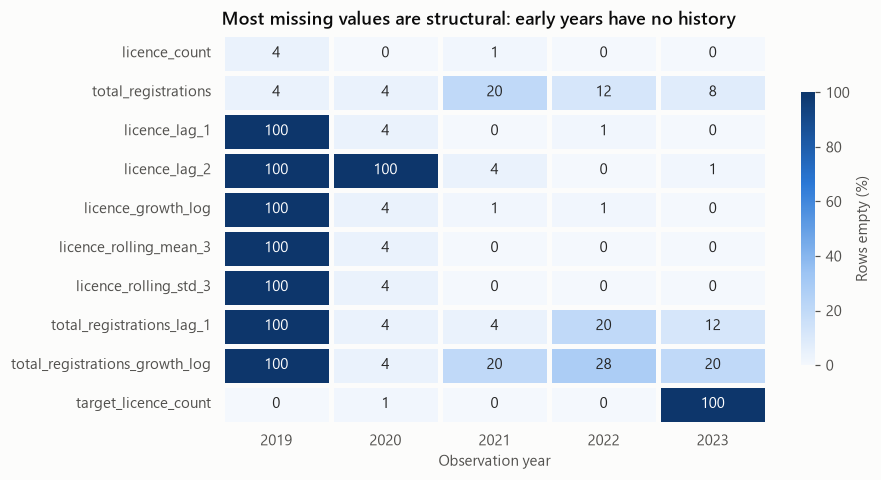

Saved fig01_missing_by_feature_and_year.png


In [5]:
share = df.groupby("year")[columns_to_check].apply(lambda g: g.isna().mean() * 100).T
fig, ax = plt.subplots(figsize=(8, 4.6))
sns.heatmap(share, annot=True, fmt=".0f", cmap=BLUE_RAMP, vmin=0, vmax=100, linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "Rows empty (%)", "shrink": 0.7}, ax=ax)
ax.set(title="Most missing values are structural: early years have no history", xlabel="Observation year", ylabel="")
ax.grid(False)
save_figure(fig, "missing_by_feature_and_year")

**What it shows.** The share of empty values for each feature and year. The dark cells sit in the earliest years, for the lag, growth and rolling features, and in 2023 for the target.

**Why it matters.** Most gaps are expected: a two-year lag cannot exist in 2019 or 2020, and 2023 has no following year. Only a small share reflects data problems: 4 rejected licence values and 12 unverified Totals, which appear as 36 rows.

,Target only,+ current licences,"+ licence lag, growth, rolling",+ two-year lag,+ registrations
target_year,,,,,
2020,75,72,0,0,0
2021,74,74,71,0,68
2022,75,74,74,71,59
2023,75,75,74,74,53
All,299,295,219,145,180


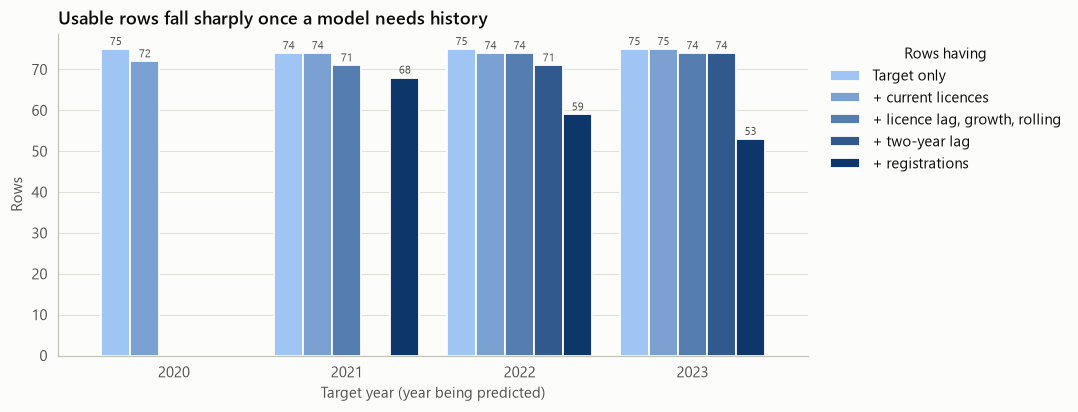

Saved fig02_usable_rows_by_feature_set.png


In [6]:
licence_core = ["licence_count", "licence_lag_1", "licence_growth_log", "licence_rolling_mean_3", "licence_rolling_std_3"]
registration_set = ["total_registrations", "total_registrations_lag_1", "total_registrations_growth_log"]
feature_sets = {
    "Target only": [],
    "+ current licences": ["licence_count"],
    "+ licence lag, growth, rolling": licence_core,
    "+ two-year lag": licence_core + ["licence_lag_2"],
    "+ registrations": licence_core + registration_set,
}
labelled = df[df["has_target"]]
usable = pd.DataFrame({name: labelled[cols].notna().all(axis=1).groupby(labelled["target_year"]).sum() if cols
                       else labelled.groupby("target_year").size() for name, cols in feature_sets.items()})
usable.loc["All"] = usable.sum()
display(usable)

fig, ax = plt.subplots(figsize=(8.8, 3.8))
colours = sns.blend_palette(["#9ec5f4", "#0d366b"], n_colors=len(feature_sets))
usable.drop("All").plot.bar(ax=ax, color=colours, width=0.84, edgecolor=SURFACE, linewidth=1.2, rot=0)
for container in ax.containers:
    ax.bar_label(container, labels=[str(int(v)) if v else "" for v in container.datavalues], fontsize=7.5, color=MUTED, padding=1)
ax.set(title="Usable rows fall sharply once a model needs history", xlabel="Target year (year being predicted)", ylabel="Rows")
ax.legend(title="Rows having", ncol=1, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="x", visible=False)
save_figure(fig, "usable_rows_by_feature_set")

FINDINGS.update(usable_target=int(usable.loc["All", "Target only"]),
                usable_licence_features=int(usable.loc["All", "+ licence lag, growth, rolling"]),
                usable_with_lag_2=int(usable.loc["All", "+ two-year lag"]),
                usable_with_registrations=int(usable.loc["All", "+ registrations"]))

**What it shows.** How many rows remain for each target year as a model requires more features.

**Why it matters.** The headline of 299 target values overstates what a model with history features can use. With lag, growth and rolling features the total is 219 rows, with registrations added it is 180, and using the two-year lag instead gives 145.

In [7]:
# Exact repeats, which a duplicate-key check cannot see.
wide = df.pivot_table(index=["district", "year"], columns="vehicle_type", values="licence_count_printed")
repeated = wide[wide.duplicated(keep=False)].sort_values(VEHICLES)
print("District-years whose three licence values exactly match another district-year:")
display(repeated)

series = df.sort_values(key)
same_as_previous = series.groupby(["district", "vehicle_type"])["licence_count_printed"].diff() == 0
print("Series values identical to the previous year:")
display(series.loc[same_as_previous, key + ["licence_count_printed", "licence_flag_ids"]])
FINDINGS.update(values_identical_to_previous_year=int(same_as_previous.sum()), copied_district_year_groups=int(len(repeated) / 2))

District-years whose three licence values exactly match another district-year:


vehicle_type          Car  Motorcycle  Three-wheeler
district    year                                    
Kilinochchi 2020    361.0     23786.0         1601.0
Mullaitivu  2019    361.0     23786.0         1601.0
Kandy       2022  52858.0    120945.0        78853.0
            2023  52858.0    120945.0        78853.0

Series values identical to the previous year:


,district,year,vehicle_type,licence_count_printed,licence_flag_ids
154,Kandy,2023,Car,52858.0,L03
159,Kandy,2023,Motorcycle,120945.0,L03
164,Kandy,2023,Three-wheeler,78853.0,L03


**Reading the tables.** No key is duplicated, but two exact copies exist that a key check cannot see. Kandy 2023 repeats Kandy 2022 in all three categories, and Mullaitivu 2019 repeats Kilinochchi 2020. Both are already flagged in the corrections file (L03, L04 and L05).

### Finding 1: Missing values are mostly structural, but they shrink the usable data

**1. What did we discover?** There are no duplicate keys. Only 4 of 375 licence values are missing, all by approved decision (Ampara 2019 and Jaffna 2021 motorcycles). However, rows usable for modelling fall from 299 to 219 once lag, growth and rolling features are required, and to 180 with registrations.

**2. Why does it matter?** The true sample size depends on the features chosen, and it decides how many validation folds are possible.

**3. How could it affect our ML methodology?** With full licence features the first usable target year is 2021, which leaves room for only two rolling-origin folds (train on 2021 and test on 2022, then train on 2021-2022 and test on 2023). Feature sets must be compared on the same rows, or a model could look better simply because it was tested on easier rows. Missing values must not be filled in.

**Observation or assumption?** **Observation:** the counts. **Assumption:** none. The fold count follows from the data once a validation design is chosen.

## 4. Revenue-licence distribution

Skewness: raw 2.29, log10 -0.85
Mean 57,830, median 31,233, min 254, max 394,975


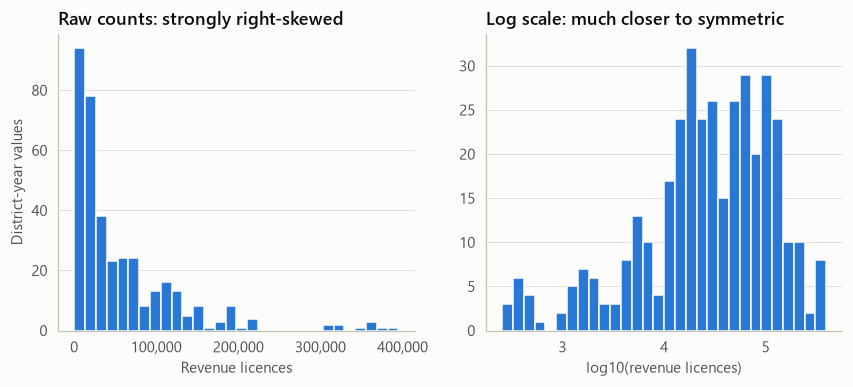

Saved fig03_licence_distribution_raw_and_log.png


In [8]:
values = df["licence_count"].dropna()
skew_raw, skew_log = stats.skew(values), stats.skew(np.log10(values))
print(f"Skewness: raw {skew_raw:.2f}, log10 {skew_log:.2f}")
print(f"Mean {values.mean():,.0f}, median {values.median():,.0f}, min {values.min():,.0f}, max {values.max():,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.5))
axes[0].hist(values, bins=30, color=BLUE, edgecolor=SURFACE, linewidth=1)
axes[0].set(title="Raw counts: strongly right-skewed", xlabel="Revenue licences", ylabel="District-year values")
thousands(axes[0], "x")
axes[1].hist(np.log10(values), bins=30, color=BLUE, edgecolor=SURFACE, linewidth=1)
axes[1].set(title="Log scale: much closer to symmetric", xlabel="log10(revenue licences)", ylabel="")
for ax in axes:
    ax.grid(axis="x", visible=False)
save_figure(fig, "licence_distribution_raw_and_log")
FINDINGS.update(skew_raw=round(float(skew_raw), 2), skew_log=round(float(skew_log), 2),
                licence_mean=round(float(values.mean())), licence_median=round(float(values.median())),
                licence_min=int(values.min()), licence_max=int(values.max()))

**What it shows.** All licence values on the raw scale (left) and the log scale (right). Skewness is 2.29 on the raw scale and -0.85 on the log scale.

**Why it matters.** A few very large districts dominate raw values: the mean (57,830) is nearly twice the median (31,233). On a raw scale, errors in big districts would dominate any model or metric.

### Finding 2: Licence counts are strongly right-skewed

**1. What did we discover?** Values range from 254 to 394,975, with a skewness of 2.29. A log scale reduces the skew to -0.85, which is smaller and now slightly to the left, because of a group of very small values.

**2. Why does it matter?** Raw-scale metrics such as RMSE would mostly reflect Gampaha, Colombo and Kurunegala, and would say little about smaller districts.

**3. How could it affect our ML methodology?** Consider training on a log scale, as already planned, while reporting results in raw counts. Use scale-independent metrics such as MAPE or MASE alongside MAE. Linear models will probably need the log transform; tree models do not need it for inputs, but the target scale still affects them.

**Observation or assumption?** **Observation:** the skewness and range. **Assumption:** that a log transform will improve modelling, which must be tested in the ML phase.

## 5. Vehicle-type comparison

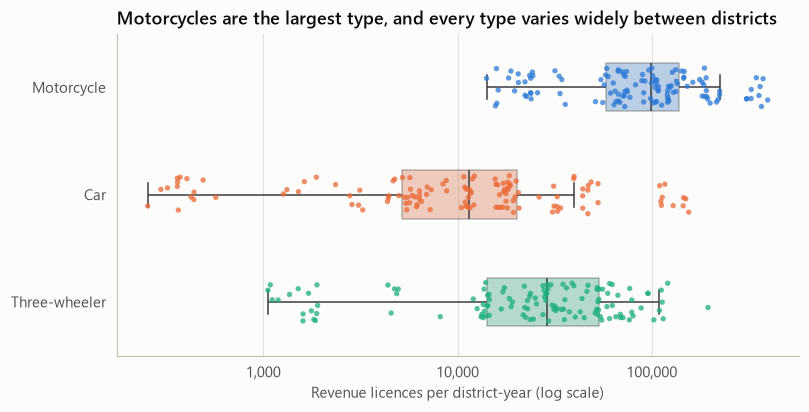

Saved fig04_licences_by_vehicle_type.png


,count,median,mean,min,max,largest / smallest
vehicle_type,,,,,,
Motorcycle,123,98598.0,113471.0,14102.0,394975.0,28.0
Car,124,11428.0,23290.0,254.0,154948.0,610.0
Three-wheeler,124,28827.0,37178.0,1056.0,194704.0,184.0


Kruskal-Wallis across vehicle types: H = 148.9, p = 4.7e-33 (rows in a series are not independent, so treat p as descriptive)


In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=df, y="vehicle_type", x="licence_count", order=VEHICLES, hue="vehicle_type", palette=VEHICLE_COLOURS,
            legend=False, width=0.45, fliersize=0, linewidth=1, boxprops={"alpha": 0.35}, ax=ax)
sns.stripplot(data=df, y="vehicle_type", x="licence_count", order=VEHICLES, hue="vehicle_type", palette=VEHICLE_COLOURS,
              legend=False, size=3.5, jitter=0.18, alpha=0.75, ax=ax)
ax.set_xscale("log")
thousands(ax, "x")
ax.set(title="Motorcycles are the largest type, and every type varies widely between districts",
       xlabel="Revenue licences per district-year (log scale)", ylabel="")
ax.grid(axis="y", visible=False)
save_figure(fig, "licences_by_vehicle_type")

by_vehicle = df.groupby("vehicle_type")["licence_count"].agg(["count", "median", "mean", "min", "max"]).loc[VEHICLES].round(0)
by_vehicle["largest / smallest"] = (by_vehicle["max"] / by_vehicle["min"]).round(0)
display(by_vehicle)
kw = stats.kruskal(*[df.loc[df["vehicle_type"] == v, "licence_count"].dropna() for v in VEHICLES])
print(f"Kruskal-Wallis across vehicle types: H = {kw.statistic:.1f}, p = {kw.pvalue:.2g} (rows in a series are not independent, so treat p as descriptive)")
FINDINGS["median_by_vehicle"] = {v: float(by_vehicle.loc[v, "median"]) for v in VEHICLES}

**What it shows.** Each dot is one district-year. The box marks the middle half of values for that vehicle type. The horizontal axis is logarithmic.

**Why it matters.** Typical values differ greatly by type: medians are 98,598 motorcycles, 28,827 three-wheelers and 11,428 cars. The spread also differs: the largest value is 28 times the smallest for motorcycles but 610 times for cars.

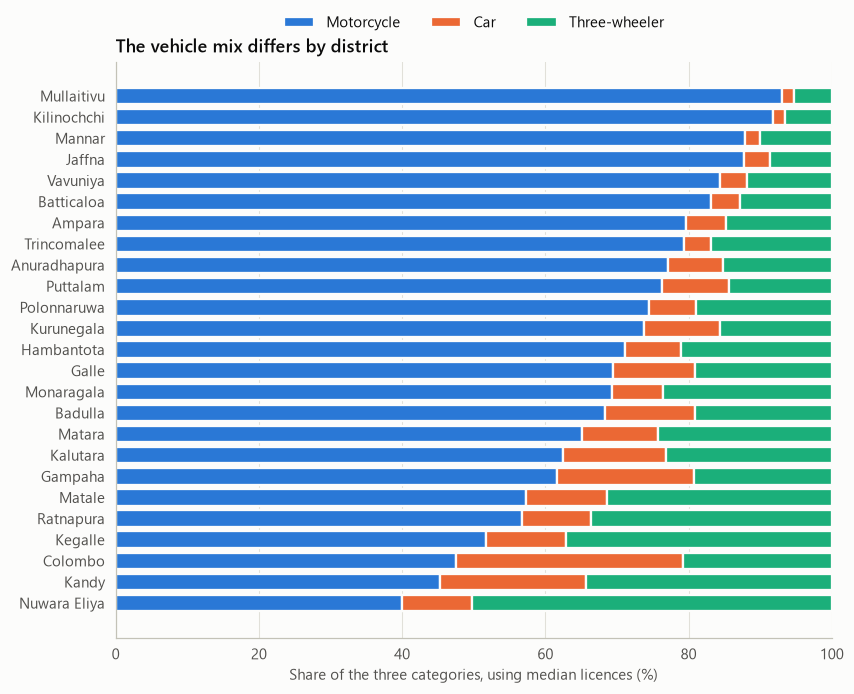

Saved fig05_vehicle_mix_by_district.png


vehicle_type,Motorcycle,Car,Three-wheeler
district,,,
Nuwara Eliya,40.0,9.8,50.3
Kandy,45.3,20.4,34.3
Colombo,47.6,31.7,20.8
Mannar,87.8,2.1,10.1
Kilinochchi,91.7,1.7,6.6
Mullaitivu,93.0,1.7,5.3


In [10]:
# Each district's typical mix: median licences across its available years.
typical = df.groupby(["district", "vehicle_type"])["licence_count"].median().unstack()[VEHICLES]
mix = typical.div(typical.sum(axis=1), axis=0) * 100
mix = mix.sort_values("Motorcycle")
fig, ax = plt.subplots(figsize=(8.4, 6.8))
left = np.zeros(len(mix))
for vehicle in VEHICLES:
    ax.barh(mix.index, mix[vehicle], left=left, color=VEHICLE_COLOURS[vehicle], edgecolor=SURFACE, linewidth=1.5, height=0.78, label=vehicle)
    left += mix[vehicle].to_numpy()
ax.set(title="The vehicle mix differs by district", xlabel="Share of the three categories, using median licences (%)", ylabel="", xlim=(0, 100))
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.03))
ax.grid(axis="y", visible=False)
save_figure(fig, "vehicle_mix_by_district")
display(mix.round(1).iloc[[0, 1, 2, -3, -2, -1]])
FINDINGS.update(motorcycle_share_min=round(float(mix["Motorcycle"].min()), 1), motorcycle_share_max=round(float(mix["Motorcycle"].max()), 1),
                motorcycle_share_min_district=mix["Motorcycle"].idxmin(), motorcycle_share_max_district=mix["Motorcycle"].idxmax())

**What it shows.** Each district's typical share across the three vehicle types, sorted by motorcycle share.

**Why it matters.** The mix varies widely, from 40.0% motorcycles in Nuwara Eliya to 93.0% in Mullaitivu. Colombo has an unusually large car share (31.7%), and three-wheelers are the largest type in Nuwara Eliya (50.3%). A mechanic's opportunity therefore depends on their specialism, not only on district size.

### Finding 3: Vehicle types behave like different populations

**1. What did we discover?** Motorcycles are the largest category, and cars are the most unevenly spread. The mix within districts also differs: motorcycle share runs from 40.0% to 93.0%.

**2. Why does it matter?** A single ranking across all vehicles would hide the opportunity for a specific kind of mechanic, which is the project's core user question.

**3. How could it affect our ML methodology?** Keep `vehicle_type` as a required input, and report all results per vehicle type as well as overall. Compare one combined model against separate models, bearing in mind that separate models have about a third of the data each.

**Observation or assumption?** **Observation:** the medians and shares. **Assumption:** that vehicle share reflects demand for each mechanic specialism. Licences show vehicles, not repairs.

## 6. District comparison

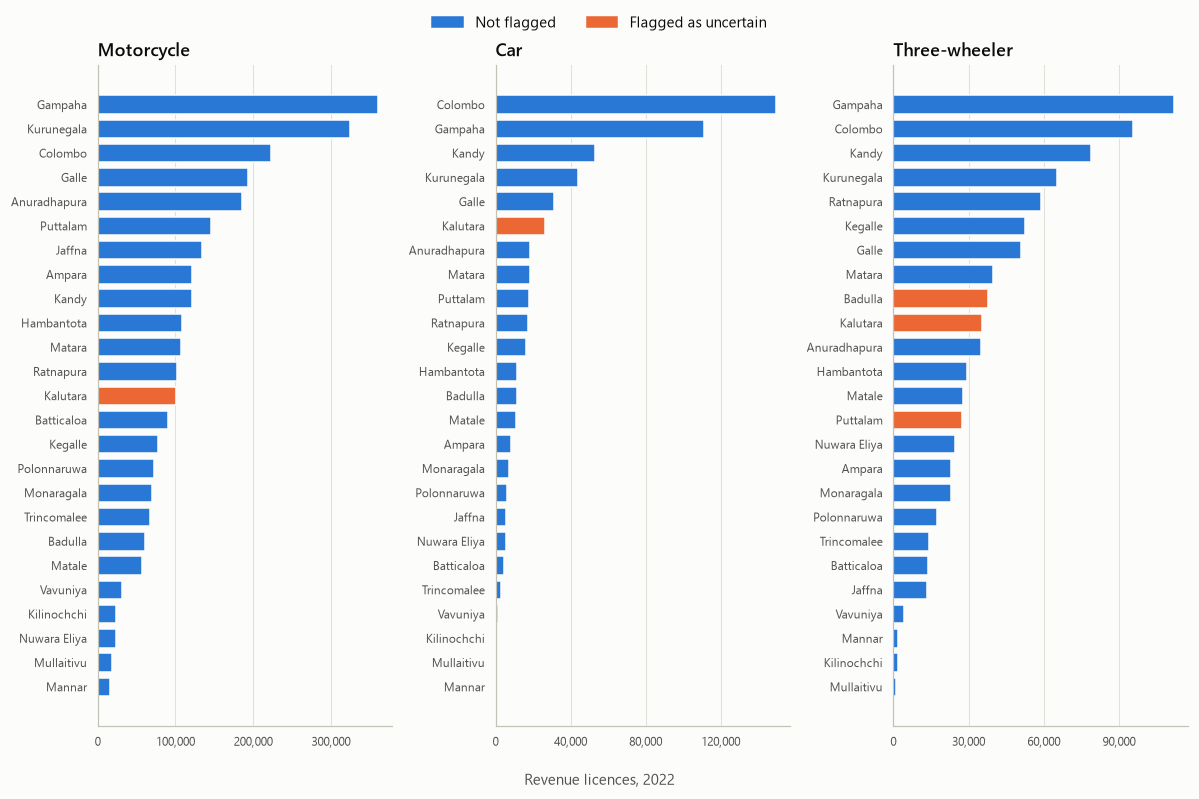

Saved fig06_district_ranking_2022.png


In [11]:
# 2022 is shown because it has complete values and no identical-year problem. Flagged values are marked.
YEAR = 2022
fig, axes = plt.subplots(1, 3, figsize=(11, 7), sharey=False)
for ax, vehicle in zip(axes, VEHICLES):
    part = df[(df["vehicle_type"] == vehicle) & (df["year"] == YEAR)].sort_values("licence_count")
    colours = [ORANGE if f else BLUE for f in part["licence_flagged"]]
    ax.barh(part["district"], part["licence_count"], color=colours, edgecolor=SURFACE, linewidth=1, height=0.76)
    ax.set_title(vehicle)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)
    thousands(ax, "x")
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.tick_params(axis="x", labelsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)]
fig.legend(handles, ["Not flagged", "Flagged as uncertain"], ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.03))
fig.supxlabel(f"Revenue licences, {YEAR}", color=MUTED, fontsize=10)
fig.tight_layout()
save_figure(fig, "district_ranking_2022")

**What it shows.** Licences by district in 2022, ranked within each vehicle type. 2022 is used because it has no missing value and no identical-year problem. Orange bars are flagged values.

**Why it matters.** Answers research question 1 directly: a small group of districts dominates each list, and the order differs by vehicle type. Flagged values are visible, including Kalutara in motorcycles, cars and three-wheelers.

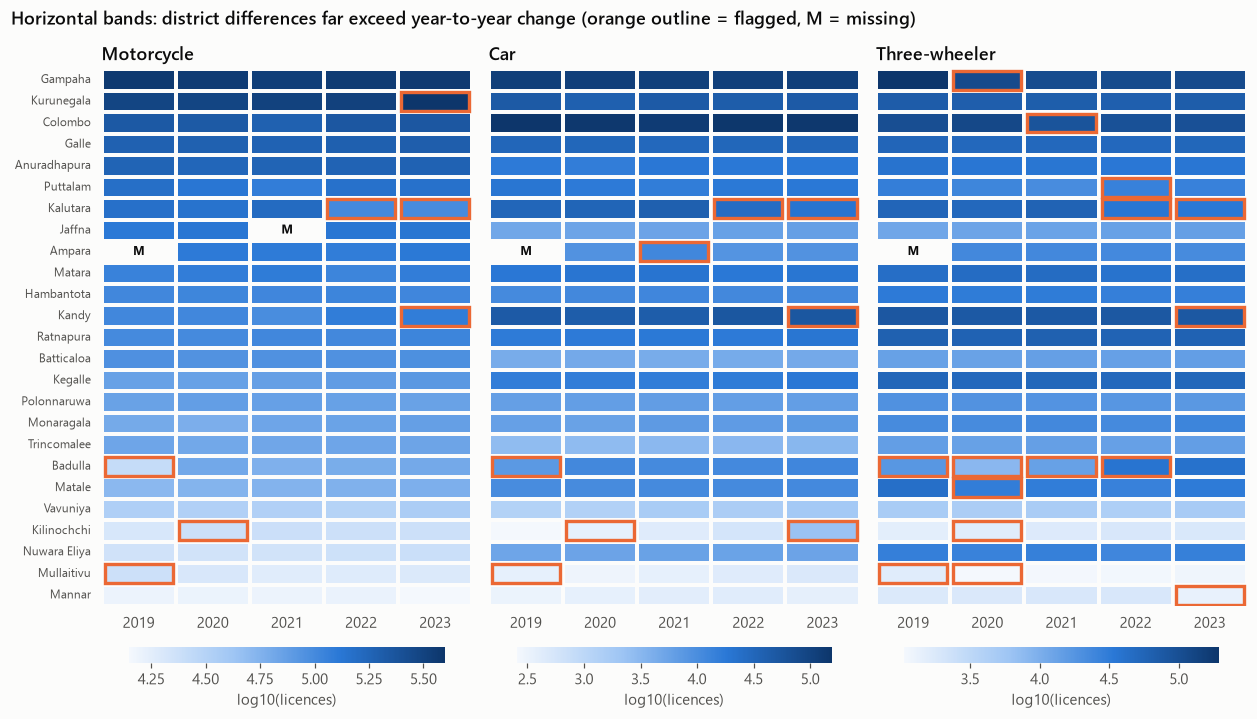

Saved fig07_district_year_heatmap.png


,districts,between_district_share_%
vehicle_type,,
Motorcycle,23,98.6
Car,24,98.7
Three-wheeler,24,98.4


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 7), sharey=True)
order = df[df["vehicle_type"] == "Motorcycle"].groupby("district")["licence_count"].median().sort_values(ascending=False).index
for ax, vehicle in zip(axes, VEHICLES):
    table = df[df["vehicle_type"] == vehicle].pivot(index="district", columns="year", values="log_licences").loc[order]
    sns.heatmap(table, cmap=BLUE_RAMP, linewidths=1.5, linecolor=SURFACE, cbar_kws={"label": "log10(licences)", "orientation": "horizontal", "pad": 0.06, "shrink": 0.85}, ax=ax)
    flags = df[(df["vehicle_type"] == vehicle) & df["licence_flagged"]]
    for row in flags.itertuples():
        column, line = list(table.columns).index(row.year), list(table.index).index(row.district)
        ax.add_patch(plt.Rectangle((column + 0.04, line + 0.06), 0.92, 0.88, fill=False, edgecolor=ORANGE, linewidth=2.2))
    missing = df[(df["vehicle_type"] == vehicle) & df["licence_count"].isna()]
    for row in missing.itertuples():
        ax.text(list(table.columns).index(row.year) + 0.5, list(table.index).index(row.district) + 0.5, "M", ha="center", va="center", fontsize=8, color=INK, fontweight="bold")
    ax.set(title=vehicle, xlabel="", ylabel="")
    ax.grid(False)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Horizontal bands: district differences far exceed year-to-year change (orange outline = flagged, M = missing)", x=0.01, ha="left", fontsize=11.5, fontweight="semibold")
fig.tight_layout()
save_figure(fig, "district_year_heatmap")

# How much of the variation in log licences lies between series rather than within them?
balanced_series = df.groupby(["district", "vehicle_type"])["licence_count"].transform(lambda s: s.notna().all())
variance_rows = []
for vehicle in VEHICLES:
    part = df[(df["vehicle_type"] == vehicle) & balanced_series]
    grand_mean = part["log_licences"].mean()
    series_means = part.groupby("district")["log_licences"].transform("mean")
    between, total = ((series_means - grand_mean) ** 2).sum(), ((part["log_licences"] - grand_mean) ** 2).sum()
    variance_rows.append({"vehicle_type": vehicle, "districts": part["district"].nunique(), "between_district_share_%": round(between / total * 100, 1)})
variance_table = pd.DataFrame(variance_rows).set_index("vehicle_type")
display(variance_table)
FINDINGS["between_district_variance_share"] = variance_table["between_district_share_%"].to_dict()

**What it shows.** Log licence counts by district and year. Colour changes little across a row but a great deal down a column. Orange outlines mark flagged values, and M marks missing values.

**Why it matters.** This is the core pattern of the dataset. In districts with complete series, between 98.4% and 98.7% of the variation in log licences lies between districts rather than across years.

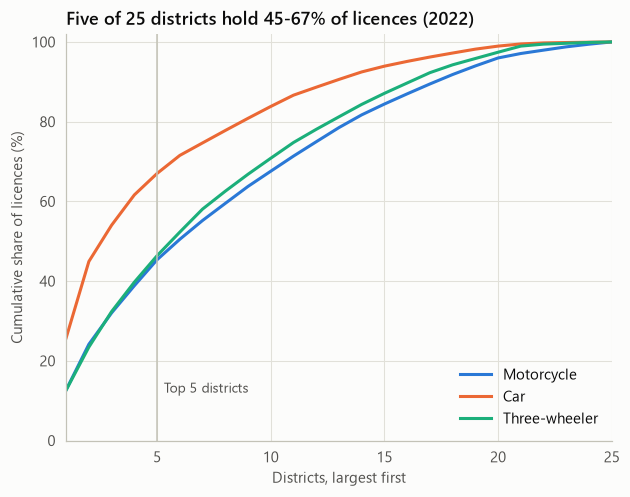

Saved fig08_district_concentration.png


,top_5_share_%,gini,largest_district,largest_/_smallest
vehicle_type,,,,
Motorcycle,45.4,0.394,Gampaha,22.3
Car,67.0,0.623,Colombo,351.9
Three-wheeler,46.4,0.430,Gampaha,100.7


In [13]:
def gini(values):
    ordered = np.sort(values)
    n = len(ordered)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(ordered) / (n * ordered.sum()))

fig, ax = plt.subplots(figsize=(6.4, 4.8))
concentration = []
for vehicle in VEHICLES:
    values = df[(df["vehicle_type"] == vehicle) & (df["year"] == YEAR)]["licence_count"].dropna().sort_values(ascending=False)
    cumulative = values.cumsum() / values.sum() * 100
    ax.plot(range(1, len(values) + 1), cumulative, color=VEHICLE_COLOURS[vehicle], label=vehicle)
    concentration.append({"vehicle_type": vehicle, "top_5_share_%": round(float(cumulative.iloc[4]), 1), "gini": round(gini(values.to_numpy()), 3),
                          "largest_district": df.loc[values.index[0], "district"], "largest_/_smallest": round(float(values.iloc[0] / values.iloc[-1]), 1)})
ax.axvline(5, color=AXIS, linewidth=1)
ax.text(5.3, 12, "Top 5 districts", color=MUTED, fontsize=9)
ax.set(title=f"Five of 25 districts hold 45-67% of licences ({YEAR})", xlabel="Districts, largest first", ylabel="Cumulative share of licences (%)", ylim=(0, 102), xlim=(1, 25))
ax.legend(loc="lower right")
save_figure(fig, "district_concentration")
concentration_table = pd.DataFrame(concentration).set_index("vehicle_type")
display(concentration_table)
FINDINGS["top_5_share_2022"] = concentration_table["top_5_share_%"].to_dict()
FINDINGS["gini_2022"] = concentration_table["gini"].to_dict()
FINDINGS["largest_to_smallest_2022"] = concentration_table["largest_/_smallest"].to_dict()

**What it shows.** The cumulative share of licences as districts are added, largest first.

**Why it matters.** The top 5 of 25 districts hold 45.4% of motorcycle licences, 46.4% of three-wheelers and 67.0% of cars. Cars are the most concentrated, with a Gini coefficient of 0.623. The largest district has 22 times as many motorcycle licences as the smallest, and 352 times as many cars.

### Finding 4: District differences far outweigh changes over time

**1. What did we discover?** Over 98% of the variation in log licences is between districts. The top 5 districts hold 45-67% of licences, depending on vehicle type.

**2. Why does it matter?** Licence counts mainly describe how large a district is. Any model will achieve a high R-squared simply by remembering district size, which could wrongly look like skill.

**3. How could it affect our ML methodology?** R-squared on levels should not be used as evidence of forecasting skill. Models must be compared with a simple baseline, and also scored on next-year change. A district identifier should be avoided or treated carefully, as it would let a model memorise district size.

**Observation or assumption?** **Observation:** the variance share and concentration. **Assumption:** none in the calculation. It covers series with complete values only (23, 24 and 24 districts).

## 7. Yearly trends, 2019-2023

Series in the balanced panel: 71 of 75
Series with no flagged value at all: 50


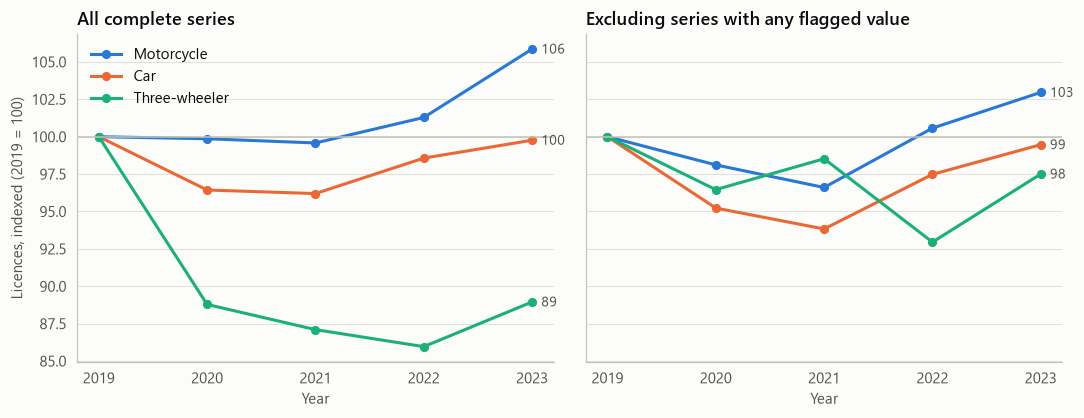

Saved fig09_national_trend_indexed.png


year,2019,2020,2021,2022,2023
vehicle_type,,,,,
Motorcycle,100.0,99.9,99.6,101.3,105.9
Car,100.0,96.4,96.2,98.6,99.8
Three-wheeler,100.0,88.8,87.1,86.0,89.0


year,2019,2020,2021,2022,2023
vehicle_type,,,,,
Motorcycle,100.0,98.1,96.6,100.6,103.0
Car,100.0,95.2,93.8,97.5,99.5
Three-wheeler,100.0,96.5,98.5,93.0,97.5


In [14]:
# A balanced panel keeps the same districts in every year, so a missing value cannot fake a trend.
complete = df.groupby(["district", "vehicle_type"])["licence_count"].transform(lambda s: s.notna().all())
balanced = df[complete]
clean_series = balanced.groupby(["district", "vehicle_type"])["licence_flagged"].transform(lambda s: not s.any())
print("Series in the balanced panel:", balanced.groupby(["district", "vehicle_type"]).ngroups, "of 75")
print("Series with no flagged value at all:", balanced[clean_series].groupby(["district", "vehicle_type"]).ngroups)

def index_2019(frame):
    totals = frame.groupby(["vehicle_type", "year"])["licence_count"].sum().unstack()
    return totals.div(totals[2019], axis=0).loc[VEHICLES] * 100

index_all, index_clean = index_2019(balanced), index_2019(balanced[clean_series])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
for ax, table, title in zip(axes, (index_all, index_clean), ("All complete series", "Excluding series with any flagged value")):
    for vehicle in VEHICLES:
        ax.plot(table.columns, table.loc[vehicle], marker="o", markersize=5, color=VEHICLE_COLOURS[vehicle], label=vehicle)
        ax.annotate(f"{table.loc[vehicle, 2023]:.0f}", (2023, table.loc[vehicle, 2023]), xytext=(6, -3), textcoords="offset points", fontsize=9, color=MUTED)
    ax.axhline(100, color=AXIS, linewidth=1)
    ax.set(title=title, xlabel="Year", xticks=sorted(df["year"].unique()))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Licences, indexed (2019 = 100)")
axes[0].legend(loc="upper left")
fig.tight_layout()
save_figure(fig, "national_trend_indexed")
display(index_all.round(1))
display(index_clean.round(1))
FINDINGS["index_2023_all_series"] = index_all[2023].round(1).to_dict()
FINDINGS["index_2023_excluding_flagged_series"] = index_clean[2023].round(1).to_dict()

**What it shows.** Total licences indexed to 2019 = 100, for the same districts in every year. The left panel uses all complete series. The right panel leaves out any series with a flagged value. The axis starts at 85, not zero, so that small changes can be seen.

**Why it matters.** The three-wheeler story changes with data quality: a fall to 89.0 becomes 97.5 once flagged series are removed. Motorcycles move from 105.9 to 103.0, and cars barely change (99.8 and 99.5). Note that the two panels cover different districts.

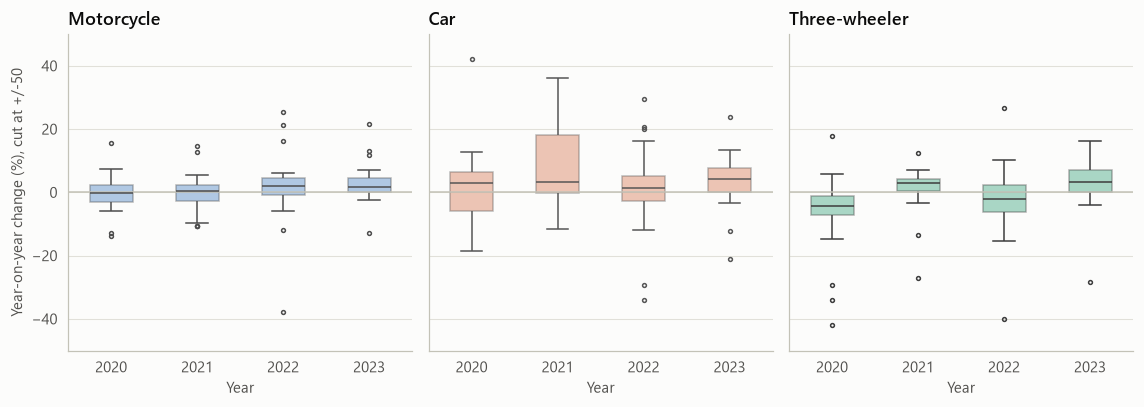

Saved fig10_growth_by_year_and_vehicle.png


,median_change,median_absolute_change
year,,
2020,-1.7,4.8
2021,2.3,3.4
2022,0.5,4.2
2023,3.2,3.9


Values beyond the +/-50% axis: 6
Overall: median absolute change 4.0%; within 5%: 58%; within 10%: 76%; n = 295


In [15]:
growth = df.dropna(subset=["licence_growth_log"]).copy()
growth["growth_pct"] = (np.exp(growth["licence_growth_log"]) - 1) * 100
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.8), sharey=True)
for ax, vehicle in zip(axes, VEHICLES):
    part = growth[growth["vehicle_type"] == vehicle]
    sns.boxplot(data=part, x="year", y="growth_pct", color=VEHICLE_COLOURS[vehicle], width=0.5, fliersize=2.5, linewidth=1, boxprops={"alpha": 0.4}, ax=ax)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set(title=vehicle, xlabel="Year", ylabel="")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Year-on-year change (%), cut at +/-50")
axes[0].set_ylim(-50, 50)
fig.tight_layout()
save_figure(fig, "growth_by_year_and_vehicle")

absolute = growth["growth_pct"].abs()
stability = growth.groupby("year")["growth_pct"].agg(median_change="median", median_absolute_change=lambda s: s.abs().median()).round(1)
display(stability)
print(f"Values beyond the +/-50% axis: {int((absolute > 50).sum())}")
print(f"Overall: median absolute change {absolute.median():.1f}%; within 5%: {(absolute <= 5).mean() * 100:.0f}%; within 10%: {(absolute <= 10).mean() * 100:.0f}%; n = {len(growth)}")
FINDINGS.update(median_absolute_change_pct=round(float(absolute.median()), 1), share_within_5_pct=round(float((absolute <= 5).mean() * 100), 1),
                share_within_10_pct=round(float((absolute <= 10).mean() * 100), 1), growth_observations=len(growth), values_beyond_50_pct=int((absolute > 50).sum()))

**What it shows.** The spread of year-on-year change between districts, for each year and vehicle type. The axis stops at +/-50%, and 6 values lie beyond it.

**Why it matters.** Most district changes are small in every year, and there is no year in which all districts moved dramatically. Changes in cars vary more than in motorcycles.

,printed_total,verified_total,verified_districts,verified_share_of_printed_%
year,,,,
2019,342064.0,338612.0,24,99.0
2020,186475.0,183237.0,24,98.3
2021,34261.0,26417.0,20,77.1
2022,20488.0,19337.0,22,94.4
2023,27871.0,27230.0,23,97.7


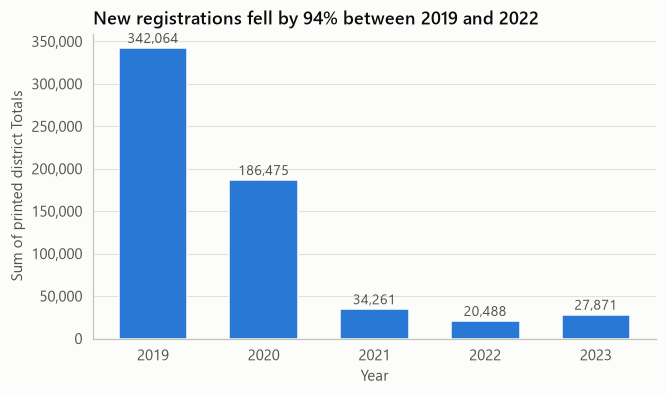

Saved fig11_registrations_by_year.png
Fall from 2019 to 2022: 94.0%


In [16]:
one_per_district = df.drop_duplicates(["district", "year"])
registrations = one_per_district.groupby("year").agg(
    printed_total=("total_registrations_printed", "sum"), verified_total=("total_registrations", "sum"), verified_districts=("total_registrations", "count"))
registrations["verified_share_of_printed_%"] = (registrations["verified_total"] / registrations["printed_total"] * 100).round(1)
display(registrations)

fig, ax = plt.subplots(figsize=(6.6, 3.6))
ax.bar(registrations.index, registrations["printed_total"], color=BLUE, edgecolor=SURFACE, width=0.62)
for year, value in registrations["printed_total"].items():
    ax.text(year, value + 6000, f"{value:,.0f}", ha="center", fontsize=9, color=MUTED)
ax.set(title="New registrations fell by 94% between 2019 and 2022", xlabel="Year", ylabel="Sum of printed district Totals")
thousands(ax)
ax.grid(axis="x", visible=False)
save_figure(fig, "registrations_by_year")
fall = 1 - registrations.loc[2022, "printed_total"] / registrations.loc[2019, "printed_total"]
print(f"Fall from 2019 to 2022: {fall * 100:.1f}%")
FINDINGS["registrations_fall_2019_2022_pct"] = round(float(fall * 100), 1)
FINDINGS["registrations_printed_by_year"] = {int(k): int(v) for k, v in registrations["printed_total"].items()}

**What it shows.** The sum of printed district Total Registrations each year, including those not verified.

**Why it matters.** New registrations fell by 94.0% between 2019 and 2022, while licences stayed roughly flat. These two indicators therefore measure very different things, which supports using licences as the fleet proxy. It also means that registration features cover a sharp structural break.

### Finding 5: The fleet is very stable, but registrations are not

**1. What did we discover?** The median year-on-year change in licences is 4.0%, and 76% of changes are within 10%. Over the same period, printed registrations fell from 342,064 to 20,488.

**2. Why does it matter?** Next year's licences will usually be very close to this year's. That makes a 'same as last year' forecast a hard benchmark to beat. The three-wheeler decline also depends on flagged values, so it should not be quoted without that caveat.

**3. How could it affect our ML methodology?** A persistence baseline is essential, and an ML model only adds value if it beats it. Registration features span a structural break, so a relationship learned in 2020 may not hold later. Results across target years should be reported separately.

**Observation or assumption?** **Observation:** the size of changes and the fall in registrations. **Assumption:** the cause. Project documents link 2020-2022 to economic conditions and import restrictions, but this data cannot show the cause, and a citation is still needed.

## 8. Outliers and suspicious data

Two approaches are compared: a simple rule on raw levels (Tukey), and a robust score on growth, computed within each vehicle type and year. These checks identify values for review. They do not change anything.

In [17]:
# Robust z-score of growth, within each vehicle type and year (Iglewicz and Hoaglin, threshold 3.5).
growth = df.dropna(subset=["licence_growth_log"]).copy()
groups = growth.groupby(["vehicle_type", "year"])["licence_growth_log"]
median, mad = groups.transform("median"), groups.transform(lambda s: (s - s.median()).abs().median())
growth["robust_z"] = 0.6745 * (growth["licence_growth_log"] - median) / mad
growth["growth_pct"] = (np.exp(growth["licence_growth_log"]) - 1) * 100
THRESHOLD = 3.5
growth["is_outlier"] = growth["robust_z"].abs() > THRESHOLD

# A row's growth also rests on last year's value, so count it as documented if either year is flagged.
previous_flag = df.sort_values(key).groupby(["district", "vehicle_type"])["licence_flagged"].shift(1, fill_value=False).astype(bool)
growth["touches_flagged_value"] = growth["licence_flagged"] | previous_flag.reindex(growth.index)
outliers = growth[growth["is_outlier"]]
undocumented = outliers[~outliers["touches_flagged_value"]].sort_values("robust_z", key=abs, ascending=False)

columns = ["district", "vehicle_type", "year", "licence_lag_1", "licence_count", "growth_pct", "robust_z"]
print(f"Outliers: {len(outliers)} of {len(growth)} growth values; already documented: {int(outliers['touches_flagged_value'].sum())}; not documented: {len(undocumented)}")
display(outliers.loc[outliers["touches_flagged_value"], columns].sort_values("robust_z", key=abs, ascending=False).round(1))
print("NEW candidates, not touching any flagged value:")
display(undocumented[columns].round(1))

flagged_growth = growth[growth["touches_flagged_value"]]
caught = int(flagged_growth["is_outlier"].sum())
print(f"Growth values touching a flagged licence: {len(flagged_growth)}, of which beyond the threshold: {caught}")

# A plain Tukey rule on raw levels mostly finds big districts, not errors.
tukey_districts = {}
for (vehicle, year), part in df.dropna(subset=["licence_count"]).groupby(["vehicle_type", "year"]):
    q1, q3 = part["licence_count"].quantile([0.25, 0.75])
    for district in part.loc[part["licence_count"] > q3 + 1.5 * (q3 - q1), "district"]:
        tukey_districts[district] = tukey_districts.get(district, 0) + 1
print("Tukey outliers on raw levels (cases per district):", dict(sorted(tukey_districts.items(), key=lambda kv: -kv[1])))
FINDINGS.update(robust_outliers=len(outliers), robust_outliers_documented=int(outliers["touches_flagged_value"].sum()), robust_outliers_new=len(undocumented),
                new_outlier_list=[f"{r.district} {r.vehicle_type} {r.year}" for r in undocumented.itertuples()],
                tukey_level_outlier_districts=sorted(tukey_districts))

Outliers: 28 of 295 growth values; already documented: 20; not documented: 8


,district,vehicle_type,year,licence_lag_1,licence_count,growth_pct,robust_z
184,Kilinochchi,Car,2023,569.0,2356.0,314.1,22.0
36,Badulla,Motorcycle,2020,25814.0,64702.0,150.6,22.0
43,Badulla,Three-wheeler,2022,13693.0,37628.0,174.8,15.5
42,Badulla,Three-wheeler,2021,8150.0,13693.0,68.0,13.7
41,Badulla,Three-wheeler,2020,17116.0,8150.0,-52.4,-13.7
143,Kalutara,Motorcycle,2022,162539.0,101043.0,-37.8,-13.5
101,Gampaha,Three-wheeler,2020,194704.0,113127.0,-41.9,-9.8
72,Colombo,Three-wheeler,2021,120716.0,88051.0,-27.1,-9.6
148,Kalutara,Three-wheeler,2022,59279.0,35497.0,-40.1,-7.4
281,Mullaitivu,Three-wheeler,2020,1601.0,1056.0,-34.0,-7.3


NEW candidates, not touching any flagged value:


,district,vehicle_type,year,licence_lag_1,licence_count,growth_pct,robust_z
158,Kandy,Motorcycle,2022,96454.0,120945.0,25.4,5.6
327,Puttalam,Three-wheeler,2021,25128.0,21759.0,-13.4,-4.8
323,Puttalam,Motorcycle,2022,120158.0,145739.0,21.3,4.7
71,Colombo,Three-wheeler,2020,102452.0,120716.0,17.8,4.1
248,Matara,Motorcycle,2022,122405.0,107687.0,-12.0,-4.0
183,Kilinochchi,Car,2022,439.0,569.0,29.6,3.9
219,Mannar,Motorcycle,2023,16190.0,14102.0,-12.9,-3.9
68,Colombo,Motorcycle,2022,192175.0,223382.0,16.2,3.5


Growth values touching a flagged licence: 38, of which beyond the threshold: 20
Tukey outliers on raw levels (cases per district): {'Gampaha': 14, 'Kurunegala': 8, 'Colombo': 6, 'Kandy': 4}


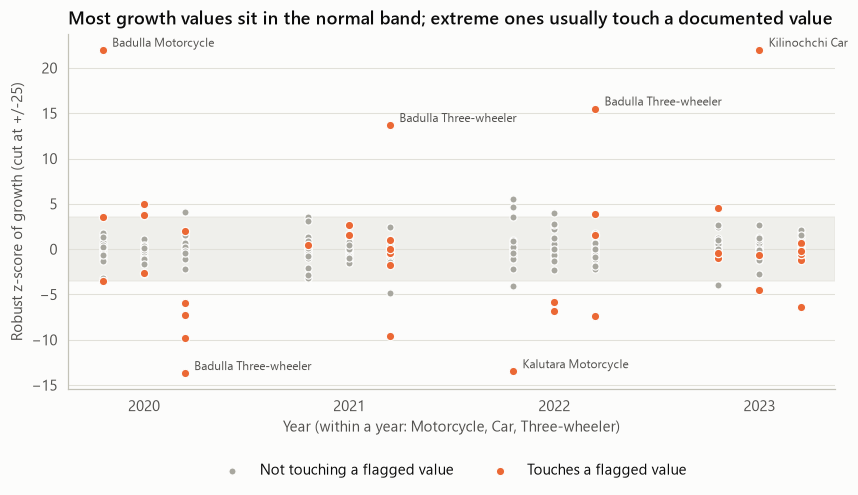

Saved fig12_growth_outliers.png


In [18]:
fig, ax = plt.subplots(figsize=(9, 4.2))
plot = growth.assign(z=growth["robust_z"].clip(-25, 25))
for documented, label, colour, size in ((False, "Not touching a flagged value", GREY, 22), (True, "Touches a flagged value", ORANGE, 30)):
    part = plot[plot["touches_flagged_value"] == documented]
    jitter = part["year"] + part["vehicle_type"].map(dict(zip(VEHICLES, (-0.2, 0, 0.2))))
    ax.scatter(jitter, part["z"], s=size, color=colour, label=label, edgecolor=SURFACE, linewidth=0.8, zorder=3 if documented else 2)
ax.axhspan(-THRESHOLD, THRESHOLD, color=GRID, alpha=0.45, zorder=0)
for row in plot[plot["is_outlier"]].sort_values("z", key=abs, ascending=False).head(6).itertuples():
    ax.annotate(f"{row.district} {row.vehicle_type}", (row.year + {"Motorcycle": -0.2, "Car": 0, "Three-wheeler": 0.2}[row.vehicle_type], row.z), xytext=(6, 2), textcoords="offset points", fontsize=8, color=MUTED)
ax.set(title="Most growth values sit in the normal band; extreme ones usually touch a documented value",
       xlabel="Year (within a year: Motorcycle, Car, Three-wheeler)", ylabel="Robust z-score of growth (cut at +/-25)", xticks=[2020, 2021, 2022, 2023])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
ax.grid(axis="x", visible=False)
save_figure(fig, "growth_outliers")

**What it shows.** The robust z-score of each growth value. The grey band is the normal range (+/-3.5). Orange dots are values that touch a flagged licence value, in that year or the year before.

**Why it matters.** Most extreme growth values were already documented in Step 2. The check also finds 8 new candidates. Some are fairly small in absolute terms (12-16%), because the normal range in some years is very narrow.

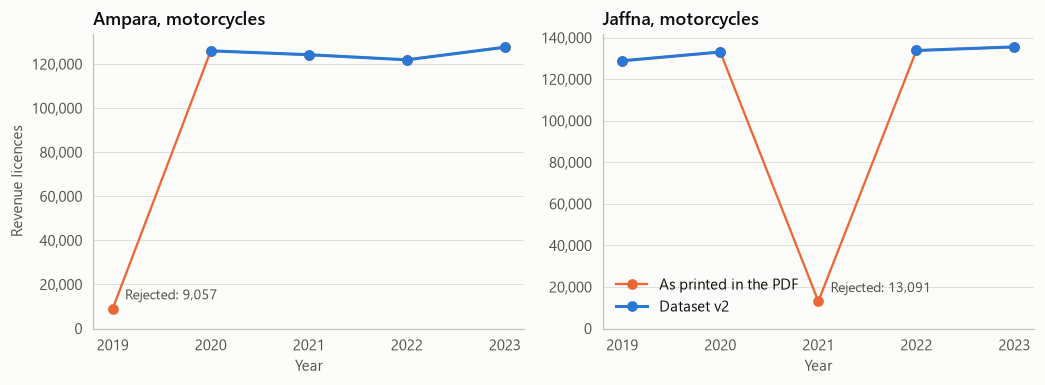

Saved fig13_effect_of_approved_corrections.png


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
for ax, (district, vehicle) in zip(axes, (("Ampara", "Motorcycle"), ("Jaffna", "Motorcycle"))):
    part = df[(df["district"] == district) & (df["vehicle_type"] == vehicle)].sort_values("year")
    ax.plot(part["year"], part["licence_count_printed"], marker="o", color=ORANGE, linewidth=1.5, label="As printed in the PDF")
    ax.plot(part["year"], part["licence_count"], marker="o", markersize=6, color=BLUE, label="Dataset v2")
    rejected = part[part["licence_count"].isna()]
    for row in rejected.itertuples():
        ax.annotate(f"Rejected: {row.licence_count_printed:,.0f}", (row.year, row.licence_count_printed), xytext=(8, 6), textcoords="offset points", fontsize=9, color=MUTED)
    ax.set(title=f"{district}, motorcycles", xlabel="Year", ylim=(0, None), xticks=part["year"])
    thousands(ax)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Revenue licences")
axes[1].legend(loc="lower left")
fig.tight_layout()
save_figure(fig, "effect_of_approved_corrections")

**What it shows.** Printed values against Dataset v2 for the two series with a value rejected as clearly incorrect.

**Why it matters.** These show why those decisions were made. Ampara 2019 (9,057) and Jaffna 2021 (13,091) sit far from the rest of their series. Without the corrections, growth rates around those years would be enormous, and would badly distort any growth feature.

### Finding 6: Level-based outlier rules mislead; growth-based rules are more useful

**1. What did we discover?** A Tukey rule on levels only identifies Gampaha, Kurunegala, Colombo and Kandy, which are simply large districts. A robust score on growth finds 28 outliers out of 295, of which 20 touch an already flagged value. Another 8 are new candidates: Kandy motorcycles 2022, Puttalam three-wheelers 2021, Puttalam motorcycles 2022, Colombo three-wheelers 2020, Matara motorcycles 2022, Kilinochchi cars 2022, Mannar motorcycles 2023 and Colombo motorcycles 2022.

**2. Why does it matter?** Removing 'outliers' by level would delete real, important districts. The new candidates may be genuine changes, so they should not be removed without evidence.

**3. How could it affect our ML methodology?** Do not remove outliers automatically. Prefer robust loss functions and metrics, such as MAE or Huber, because the tails are long. The 8 candidates should be reviewed against the PDFs and documented before the final evaluation.

**Observation or assumption?** **Observation:** which values exceed the threshold. **Assumption:** that a large deviation suggests a data problem. It might equally be a real change, so these are only candidates. The threshold of 3.5 is a convention (Iglewicz and Hoaglin).

## 9. Feature correlations

**Development rows only (target years 2020-2022).** Relationships between features are examined first, without the target.

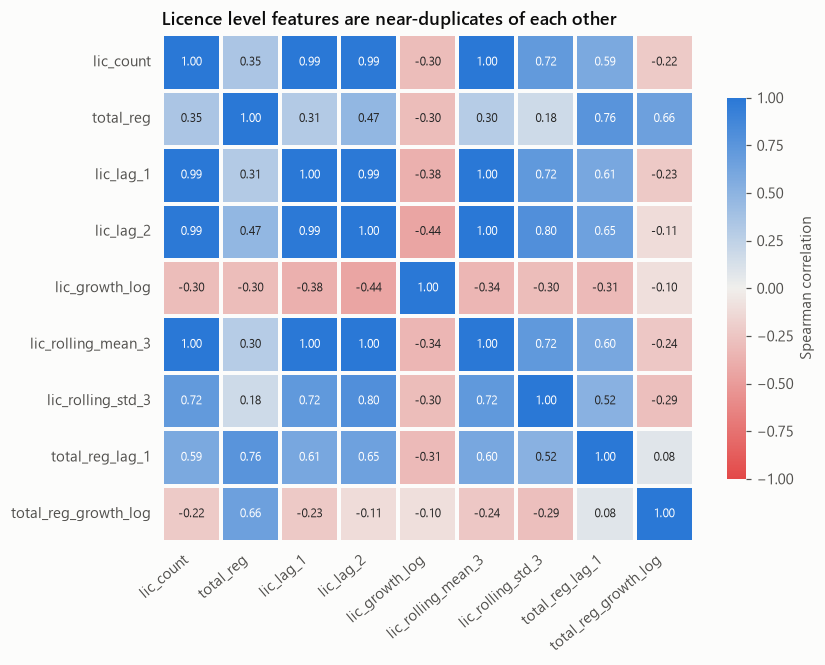

Saved fig14_feature_correlation.png
Largest gap in the growth identity: 1.8e-15
Complete development rows used: 127


,VIF
log licence_count,491.1
log licence_lag_1,400.8
log licence_rolling_mean_3,1427.8
log licence_rolling_std_3,2.4
log total_registrations,5.0
total_registrations_growth_log,4.6


,VIF after dropping lag 1 and rolling mean
log licence_count,2.6
log licence_rolling_std_3,2.3
log total_registrations,4.9
total_registrations_growth_log,4.6


In [20]:
# Development rows only. Target year 2023 is not used.
matrix = dev[FEATURES].corr(method="spearman")
pretty = [f.replace("licence_", "lic_").replace("total_registrations", "total_reg") for f in FEATURES]
fig, ax = plt.subplots(figsize=(7.8, 6))
sns.heatmap(matrix, annot=True, fmt=".2f", annot_kws={"size": 8}, cmap=DIVERGING, vmin=-1, vmax=1, linewidths=1.5, linecolor=SURFACE,
            xticklabels=pretty, yticklabels=pretty, cbar_kws={"label": "Spearman correlation", "shrink": 0.75}, ax=ax)
ax.set(title="Licence level features are near-duplicates of each other")
ax.grid(False)
plt.xticks(rotation=40, ha="right")
save_figure(fig, "feature_correlation")

# licence_growth_log is exactly log(licence_count) - log(licence_lag_1), an identity, so including all
# three would make the matrix singular. First confirm the identity, then compute VIF without growth.
complete = dev.dropna(subset=["licence_count", "licence_lag_1", "licence_growth_log"])
identity_gap = (np.log(complete["licence_count"]) - np.log(complete["licence_lag_1"]) - complete["licence_growth_log"]).abs().max()
print(f"Largest gap in the growth identity: {identity_gap:.1e}")

transformed = pd.DataFrame({
    "log licence_count": np.log(dev["licence_count"]), "log licence_lag_1": np.log(dev["licence_lag_1"]),
    "log licence_rolling_mean_3": np.log(dev["licence_rolling_mean_3"]), "log licence_rolling_std_3": np.log(dev["licence_rolling_std_3"]),
    "log total_registrations": np.log(dev["total_registrations"]), "total_registrations_growth_log": dev["total_registrations_growth_log"],
}).dropna()
vif = pd.Series(np.diag(np.linalg.inv(transformed.corr().to_numpy())), index=transformed.columns, name="VIF").round(1)
print(f"Complete development rows used: {len(transformed)}")
display(vif.to_frame())
reduced = transformed.drop(columns=["log licence_lag_1", "log licence_rolling_mean_3"])
vif_reduced = pd.Series(np.diag(np.linalg.inv(reduced.corr().to_numpy())), index=reduced.columns, name="VIF after dropping lag 1 and rolling mean").round(1)
display(vif_reduced.to_frame())
FINDINGS["spearman_level_vs_lag_1"] = round(float(matrix.loc["licence_count", "licence_lag_1"]), 3)
FINDINGS["spearman_level_vs_rolling_mean"] = round(float(matrix.loc["licence_count", "licence_rolling_mean_3"]), 3)
FINDINGS["spearman_level_vs_total_registrations"] = round(float(matrix.loc["licence_count", "total_registrations"]), 3)
FINDINGS["vif"] = vif.to_dict()
FINDINGS["vif_reduced"] = vif_reduced.to_dict()

**What it shows.** Spearman correlation between each pair of features. Blue is positive, red is negative, and grey is near zero.

**Why it matters.** `licence_count`, its lags and the rolling mean correlate at 0.99-1.00, so they carry almost the same information. Registration features are clearly different. Note that `total_registrations` correlates only 0.35 with licences, partly because it is a district-wide figure repeated across vehicle types.

### Finding 7: Licence level features are nearly duplicates

**1. What did we discover?** Correlations among level features reach 1.00. Variance inflation factors are 491 for licence count, 401 for lag 1 and 1,428 for the rolling mean. Dropping lag 1 and the rolling mean brings all remaining factors below 5. Also, `licence_growth_log` is an exact function of licence count and lag 1 (the identity holds to within 2e-15).

**2. Why does it matter?** With these features together, a linear model cannot separate their effects, and its coefficients and SHAP explanations would be unstable and hard to defend.

**3. How could it affect our ML methodology?** Start with one level feature, `licence_count`. Do not use `licence_count`, `licence_lag_1` and `licence_growth_log` together in an unregularised linear model. Ridge regression can tolerate correlated inputs, but explanations should still be reported cautiously. SHAP values are shared unpredictably between near-duplicate features in tree models.

**Observation or assumption?** **Observation:** the correlations and VIF values, computed on 127 complete development rows. **Assumption:** none. The growth identity follows from how the feature is defined.

## 10. Feature relationships with the target

**Development rows only.** Two separate questions are asked. Does a feature track next year's **level**? Does it track next year's **change**? The second is the informative one, as nearly anything tied to district size will track the level.

"Within year" removes the movement shared by a vehicle type in a given year, leaving only differences between districts. Without this step, a feature could look useful merely because it picks up a calendar effect.

Development rows with a next-year change: 220


,n,target_years,rho_with_next_level,rho_with_next_change,rho_change_within_year
feature,,,,,
licence_count,220,3,0.991,-0.250,-0.212
total_registrations,199,3,0.345,-0.120,-0.204
licence_lag_1,145,2,0.988,-0.184,-0.190
licence_lag_2,71,1,0.986,0.017,-0.084
licence_growth_log,145,2,-0.330,-0.207,-0.167
licence_rolling_mean_3,145,2,0.992,-0.201,-0.193
licence_rolling_std_3,145,2,0.722,-0.166,-0.023
total_registrations_lag_1,142,2,0.591,-0.054,-0.161
total_registrations_growth_log,130,2,-0.222,0.157,0.040


,level_Motorcycle,level_Car,level_Three-wheeler
feature,,,
licence_count,0.985,0.989,0.976
total_registrations,0.494,0.414,0.359
licence_lag_1,0.982,0.987,0.963
licence_lag_2,0.978,0.990,0.959
licence_growth_log,-0.154,-0.440,-0.237
licence_rolling_mean_3,0.983,0.988,0.969
licence_rolling_std_3,0.417,0.838,0.744
total_registrations_lag_1,0.867,0.775,0.660
total_registrations_growth_log,-0.268,-0.344,-0.337


,change_Motorcycle,change_Car,change_Three-wheeler
feature,,,
licence_count,-0.126,-0.422,-0.284
total_registrations,-0.170,-0.111,-0.086
licence_lag_1,0.017,-0.334,-0.291
licence_lag_2,0.094,-0.235,-0.169
licence_growth_log,-0.304,-0.160,-0.279
licence_rolling_mean_3,0.009,-0.356,-0.326
licence_rolling_std_3,0.066,-0.405,-0.111
total_registrations_lag_1,-0.021,-0.183,0.027
total_registrations_growth_log,-0.226,0.305,0.370


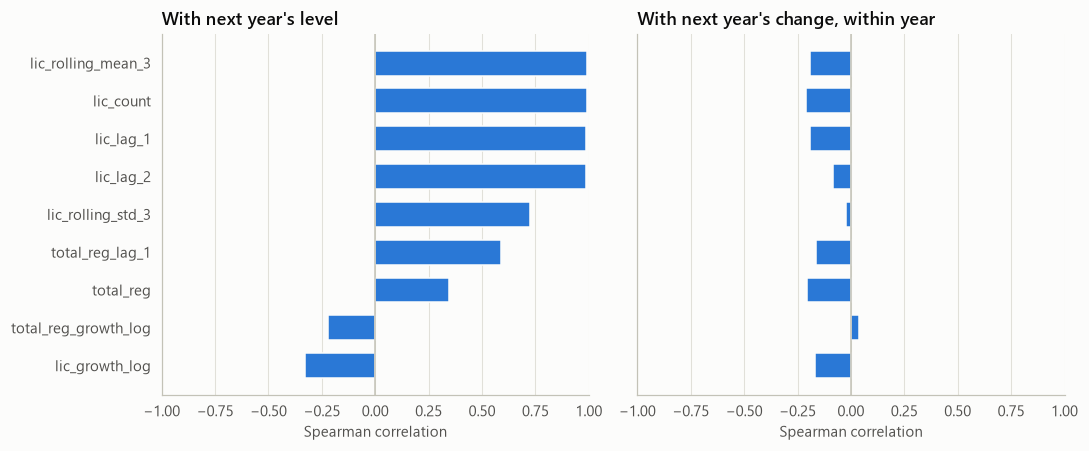

Saved fig15_feature_target_correlation.png


In [21]:
# Two questions, development rows only:
#   1. Does the feature track next year's LEVEL?  (Almost anything tied to district size will.)
#   2. Does it track next year's CHANGE?          (The harder and more informative question.)
dev_change = dev.dropna(subset=["next_log_change"])  # a change needs both this year and next year
print(f"Development rows with a next-year change: {len(dev_change)}")

def within_year(frame, column):
    """Remove the shared movement of each vehicle type and year, leaving differences between districts."""
    return frame[column] - frame.groupby(["vehicle_type", "target_year"])[column].transform("mean")

rows = []
for feature in FEATURES:
    usable_rows = dev_change[[feature, "target_licence_count", "next_log_change", "vehicle_type", "target_year"]].dropna()
    rows.append({
        "feature": feature, "n": len(usable_rows), "target_years": usable_rows["target_year"].nunique(),
        "rho_with_next_level": usable_rows[feature].corr(usable_rows["target_licence_count"], method="spearman"),
        "rho_with_next_change": usable_rows[feature].corr(usable_rows["next_log_change"], method="spearman"),
        "rho_change_within_year": within_year(usable_rows, feature).corr(within_year(usable_rows, "next_log_change"), method="spearman"),
    })
feature_target = pd.DataFrame(rows).set_index("feature")
for vehicle in VEHICLES:
    part = dev_change[dev_change["vehicle_type"] == vehicle]
    feature_target[f"level_{vehicle}"] = [part[f].corr(part["target_licence_count"], method="spearman") for f in FEATURES]
    feature_target[f"change_{vehicle}"] = [part[f].corr(part["next_log_change"], method="spearman") for f in FEATURES]
display(feature_target[["n", "target_years", "rho_with_next_level", "rho_with_next_change", "rho_change_within_year"]].round(3))
display(feature_target[[c for c in feature_target if c.startswith("level_")]].round(3))
display(feature_target[[c for c in feature_target if c.startswith("change_")]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
ordered = feature_target.sort_values("rho_with_next_level")
labels = [f.replace("licence_", "lic_").replace("total_registrations", "total_reg") for f in ordered.index]
for ax, column, title in zip(axes, ("rho_with_next_level", "rho_change_within_year"), ("With next year's level", "With next year's change, within year")):
    ax.barh(labels, ordered[column], color=BLUE, edgecolor=SURFACE, height=0.66)
    ax.axvline(0, color=AXIS, linewidth=1)
    ax.set(title=title, xlim=(-1, 1), xlabel="Spearman correlation")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save_figure(fig, "feature_target_correlation")
FINDINGS["feature_target"] = feature_target[["n", "target_years", "rho_with_next_level", "rho_with_next_change", "rho_change_within_year"]].round(3).to_dict(orient="index")

**What it shows.** Spearman correlation of each feature with next year's level (left) and with next year's change after removing shared yearly movement (right).

**Why it matters.** Level correlations are close to 1 for licence features but say little, as they mainly reflect district size. Relationships with change are all weak (between -0.21 and +0.04). This is the honest picture of how much these features can say about the future beyond 'same as last year'.

### Finding 8: No feature strongly predicts next-year change

**1. What did we discover?** Licence level features correlate about 0.99 with next year's level. With next year's change, within year, the strongest are `licence_count` (-0.21) and `total_registrations` (-0.20), and both are weak. `total_registrations_growth_log` looks like +0.16 when years are pooled, but falls to +0.04 within year, and its sign differs by vehicle type (-0.23, +0.31, +0.37).

**2. Why does it matter?** The apparent signal in registration growth is largely a calendar effect, not a difference between districts. Models may therefore struggle to add much beyond persistence.

**3. How could it affect our ML methodology?** Treat `licence_count`, `vehicle_type` and perhaps `licence_growth_log` as the core inputs. Test registration features as an add-on, on the same rows, and keep them only if they improve validation results. Drop `licence_lag_2`: it covers only one development target year (n = 71) and is unstable. Consider predicting log change rather than level. An honest conclusion may be that ML adds little here, and that is a valid research result (RQ3).

**Observation or assumption?** **Observation:** the correlations. **Assumption:** the slight negative link between size and change suggests regression to the mean, but this has not been tested. Weak correlation also does not rule out a non-linear or combined effect. Correlation does not show causation.

## 11. Target-variable distribution

Target availability by target year:


target_status,available,no_next_year,set_missing_next_year
target_year,,,
2020,75,0,0
2021,74,0,1
2022,75,0,0
2023,75,0,0
2024,0,75,0


All 299 targets: skewness raw 2.33, log10 -0.84


,count,mean,std,min,25%,50%,75%,max
vehicle_type,,,,,,,,
Motorcycle,99.0,113904.0,87910.0,14102.0,59118.0,98598.0,134706.0,394975.0
Car,100.0,23075.0,33658.0,297.0,5396.0,11546.0,20174.0,149553.0
Three-wheeler,100.0,36079.0,29470.0,1056.0,14130.0,28484.0,52684.0,120716.0


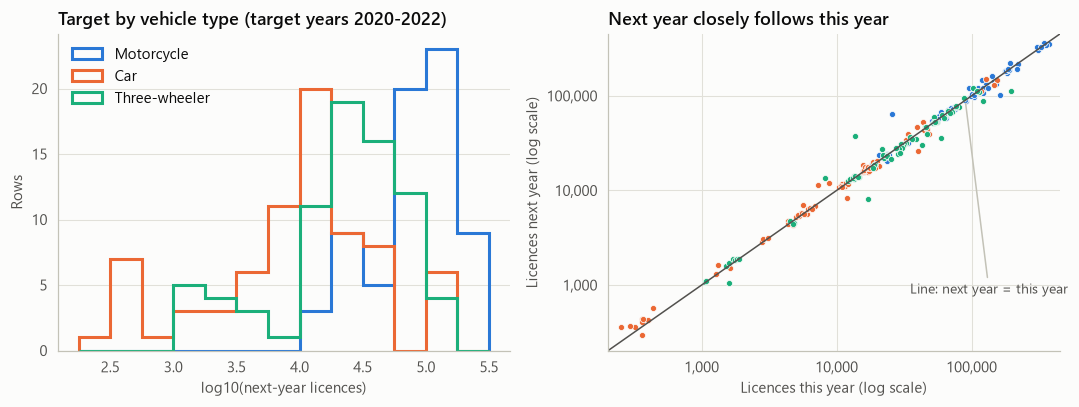

Saved fig16_target_distribution_and_persistence.png


In [22]:
print("Target availability by target year:")
display(df.groupby("target_year")["target_status"].value_counts().unstack(fill_value=0))
target_values = df["target_licence_count"].dropna()
print(f"All 299 targets: skewness raw {stats.skew(target_values):.2f}, log10 {stats.skew(np.log10(target_values)):.2f}")
display(df.groupby("vehicle_type")["target_licence_count"].describe().loc[VEHICLES].round(0))

# Shape only is shown for development rows; target year 2023 is not plotted.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for vehicle in VEHICLES:
    part = dev.loc[dev["vehicle_type"] == vehicle, "target_licence_count"]
    axes[0].hist(np.log10(part), bins=np.arange(2.25, 5.75, 0.25), histtype="step", linewidth=2, color=VEHICLE_COLOURS[vehicle], label=vehicle)
axes[0].set(title="Target by vehicle type (target years 2020-2022)", xlabel="log10(next-year licences)", ylabel="Rows")
axes[0].legend()
axes[0].grid(axis="x", visible=False)
for vehicle in VEHICLES:
    part = dev[dev["vehicle_type"] == vehicle]
    axes[1].scatter(part["licence_count"], part["target_licence_count"], s=16, color=VEHICLE_COLOURS[vehicle], edgecolor=SURFACE, linewidth=0.5, label=vehicle)
limits = (dev[["licence_count", "target_licence_count"]].min().min() * 0.8, dev[["licence_count", "target_licence_count"]].max().max() * 1.2)
axes[1].plot(limits, limits, color=MUTED, linewidth=1)
axes[1].annotate("Line: next year = this year", xy=(limits[1] * 0.2, limits[1] * 0.2), xytext=(limits[1] * 0.3, limits[0] * 4), fontsize=9, color=MUTED, ha="center", arrowprops={"arrowstyle": "-", "color": AXIS})
axes[1].set(xscale="log", yscale="log", xlim=limits, ylim=limits, title="Next year closely follows this year", xlabel="Licences this year (log scale)", ylabel="Licences next year (log scale)")
thousands(axes[1], "x")
thousands(axes[1], "y")
fig.tight_layout()
save_figure(fig, "target_distribution_and_persistence")
FINDINGS.update(target_skew_raw=round(float(stats.skew(target_values)), 2), target_skew_log=round(float(stats.skew(np.log10(target_values))), 2))

**What it shows.** Left: the target by vehicle type, on a log scale, for development rows. Right: this year's licences against next year's, also on log scales. The line marks no change.

**Why it matters.** Points hug the line closely across more than three orders of magnitude. The few points far from it are mostly flagged values: without flagged rows, the largest change in development rows is 25.4%, against 174.8% with them.

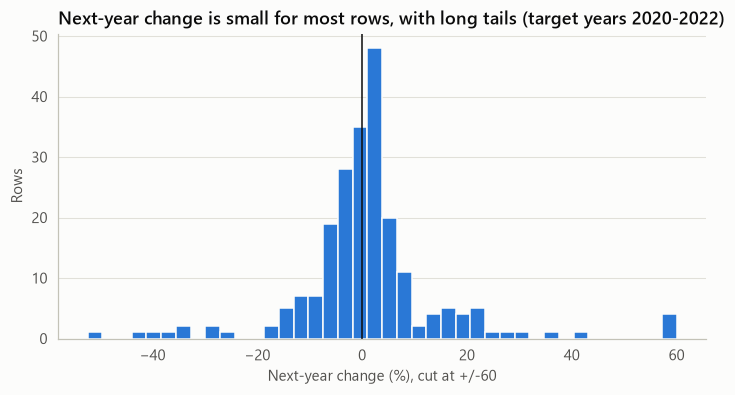

Saved fig17_next_year_change_distribution.png
n = 220; median change 0.8%; median absolute change 4.1%
Within 5%: 56%; within 10%: 76%; beyond 25%: 8%
Skewness of next_log_change: 1.06; excess kurtosis: 13.0


,median,median_absolute,n
target_year,,,
2020,-1.7,4.8,72
2021,2.3,3.4,74
2022,0.5,4.2,74


In [23]:
change = dev["next_pct_change"].dropna()
fig, ax = plt.subplots(figsize=(7.6, 3.6))
ax.hist(change.clip(-60, 60), bins=40, color=BLUE, edgecolor=SURFACE)
ax.axvline(0, color=INK, linewidth=1)
ax.set(title="Next-year change is small for most rows, with long tails (target years 2020-2022)", xlabel="Next-year change (%), cut at +/-60", ylabel="Rows")
ax.grid(axis="x", visible=False)
save_figure(fig, "next_year_change_distribution")

print(f"n = {len(change)}; median change {change.median():.1f}%; median absolute change {change.abs().median():.1f}%")
print(f"Within 5%: {(change.abs() <= 5).mean() * 100:.0f}%; within 10%: {(change.abs() <= 10).mean() * 100:.0f}%; beyond 25%: {(change.abs() > 25).mean() * 100:.0f}%")
print(f"Skewness of next_log_change: {stats.skew(dev['next_log_change'].dropna()):.2f}; excess kurtosis: {stats.kurtosis(dev['next_log_change'].dropna()):.1f}")
by_year = dev.groupby("target_year")["next_pct_change"].agg(median="median", median_absolute=lambda s: s.abs().median(), n="count").round(1)
display(by_year)
FINDINGS.update(dev_median_absolute_next_change_pct=round(float(change.abs().median()), 1), dev_share_next_within_10_pct=round(float((change.abs() <= 10).mean() * 100), 1),
                dev_share_next_beyond_25_pct=round(float((change.abs() > 25).mean() * 100), 1))

**What it shows.** The percentage change from this year to next year, for development rows. Values beyond +/-60% are placed in the last bars.

**Why it matters.** This is the quantity a model really has to predict beyond persistence. It is centred near zero (median 0.8%), with a median absolute change of 4.1%. The tails are long: 8% of rows change by more than 25%, and the excess kurtosis is 13.0.

### Finding 9: The target is highly persistent, with long tails

**1. What did we discover?** The target has the same shape as licence counts (skewness 2.33 raw, -0.84 log). In development rows, 76% of next-year changes are within 10%, while 8% exceed 25%.

**2. Why does it matter?** Typical changes are small, so typical errors should be small too, even for a naive forecast. A low MAPE on its own therefore proves little.

**3. How could it affect our ML methodology?** Report skill relative to persistence, for example with MASE. Use a robust loss. Report errors separately for ordinary rows and flagged rows, because the tails are concentrated in flagged values.

**Observation or assumption?** **Observation:** the distribution. **Assumption:** that development-period behaviour will carry into 2023, which the final test will check.

## 12. Flagged and unflagged records

Flagged licence values: 30 of 375


vehicle_type,Motorcycle,Car,Three-wheeler
flagged,7,8,15


year,2019,2020,2021,2022,2023
flagged,6,7,3,5,9


Districts with at least one flagged or missing licence value: 13 of 25


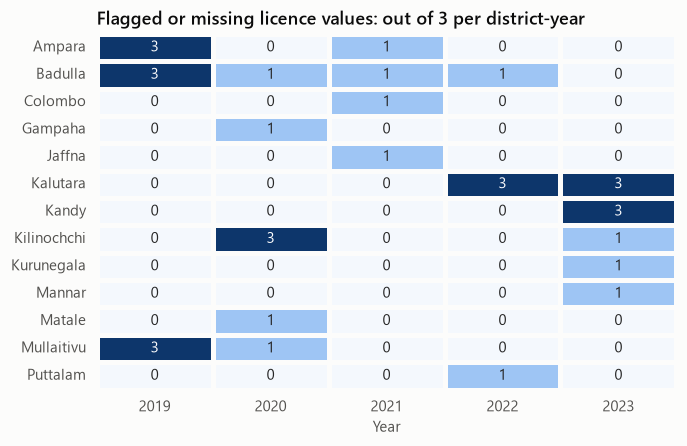

Saved fig18_flagged_values_by_district_and_year.png


In [24]:
print(f"Flagged licence values: {int(df['licence_flagged'].sum())} of {len(df)}")
display(df.groupby("vehicle_type")["licence_flagged"].sum().rename("flagged").loc[VEHICLES].to_frame().T)
display(df.groupby("year")["licence_flagged"].sum().rename("flagged").to_frame().T)

status = df.assign(state=np.select([df["licence_count"].isna(), df["licence_flagged"]], [2, 1], default=0))
districts_with_issue = status[status["state"] > 0]["district"].unique()
print(f"Districts with at least one flagged or missing licence value: {len(districts_with_issue)} of 25")
per_cell = status[status["district"].isin(districts_with_issue)].pivot_table(index="district", columns="year", values="state", aggfunc=lambda s: int((s > 0).sum()))
fig, ax = plt.subplots(figsize=(6.8, 4.2))
sns.heatmap(per_cell, annot=True, fmt="d", cmap=BLUE_RAMP, vmin=0, vmax=3, linewidths=2, linecolor=SURFACE, cbar=False, ax=ax)
ax.set(title="Flagged or missing licence values: out of 3 per district-year", xlabel="Year", ylabel="")
ax.grid(False)
save_figure(fig, "flagged_values_by_district_and_year")
FINDINGS.update(flagged_licence_values=int(df["licence_flagged"].sum()), flagged_targets=int(df["target_flagged"].sum()), districts_with_issue=int(len(districts_with_issue)),
                flagged_targets_in_hold_out=int(df.loc[df["target_year"] == HOLD_OUT_TARGET_YEAR, "target_flagged"].sum()),
                flagged_by_vehicle={v: int(df.loc[df["vehicle_type"] == v, "licence_flagged"].sum()) for v in VEHICLES})

**What it shows.** The number of flagged or missing licence values (out of 3) for each district and year. Only the 13 affected districts are shown.

**Why it matters.** Problems are not spread evenly: Ampara, Badulla, Mullaitivu, Kalutara, Kandy and Kilinochchi have whole-column issues. 2023, the future test year, has 9 flagged values, the most of any year.

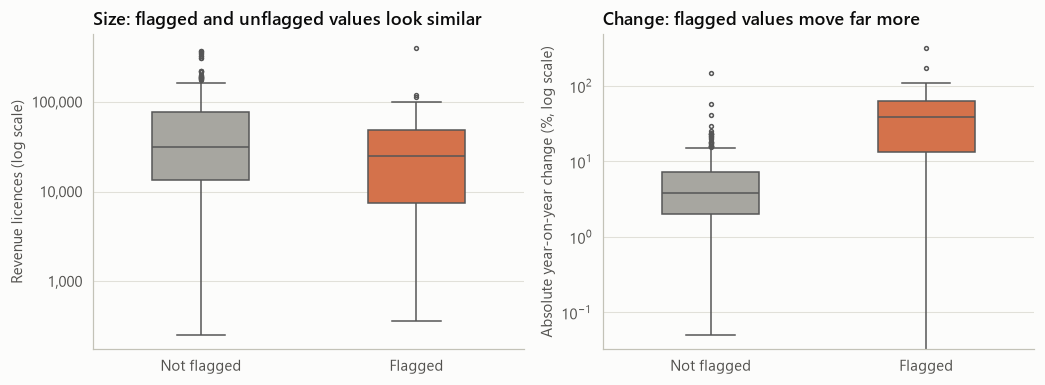

Saved fig19_flagged_vs_unflagged.png


,n_level,median_licences,n_change,median_abs_change_%
Not flagged,341,31732.0,271,3.8
Flagged,30,24800.0,24,38.3


Mann-Whitney: level p = 0.143; absolute change p = 9.97e-07


In [25]:
growth_all = df.dropna(subset=["licence_growth_log"]).assign(abs_growth=lambda d: (np.exp(d["licence_growth_log"].abs()) - 1) * 100)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
sns.boxplot(data=df.dropna(subset=["licence_count"]), x="licence_flagged", y="licence_count", hue="licence_flagged", palette=FLAG_COLOURS, legend=False, width=0.45, linewidth=1, fliersize=2.5, ax=axes[0])
axes[0].set(yscale="log", title="Size: flagged and unflagged values look similar", ylabel="Revenue licences (log scale)")
thousands(axes[0])
sns.boxplot(data=growth_all, x="licence_flagged", y="abs_growth", hue="licence_flagged", palette=FLAG_COLOURS, legend=False, width=0.45, linewidth=1, fliersize=2.5, ax=axes[1])
axes[1].set(yscale="log", title="Change: flagged values move far more", ylabel="Absolute year-on-year change (%, log scale)")
for ax in axes:
    ax.set(xlabel="", xticks=[0, 1], xticklabels=["Not flagged", "Flagged"])
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save_figure(fig, "flagged_vs_unflagged")

level_test = stats.mannwhitneyu(df.loc[df["licence_flagged"], "licence_count"].dropna(), df.loc[~df["licence_flagged"], "licence_count"].dropna())
change_test = stats.mannwhitneyu(growth_all.loc[growth_all["licence_flagged"], "abs_growth"], growth_all.loc[~growth_all["licence_flagged"], "abs_growth"])
comparison = pd.DataFrame({
    "n_level": df.dropna(subset=["licence_count"]).groupby("licence_flagged").size(),
    "median_licences": df.groupby("licence_flagged")["licence_count"].median(),
    "n_change": growth_all.groupby("licence_flagged").size(),
    "median_abs_change_%": growth_all.groupby("licence_flagged")["abs_growth"].median().round(1),
})
comparison.index = ["Not flagged", "Flagged"]
display(comparison)
print(f"Mann-Whitney: level p = {level_test.pvalue:.3g}; absolute change p = {change_test.pvalue:.3g}")
FINDINGS["flag_comparison"] = {
    "median_licences_flagged": float(comparison.loc["Flagged", "median_licences"]), "median_licences_unflagged": float(comparison.loc["Not flagged", "median_licences"]),
    "median_abs_change_flagged": float(comparison.loc["Flagged", "median_abs_change_%"]), "median_abs_change_unflagged": float(comparison.loc["Not flagged", "median_abs_change_%"]),
    "level_p": float(level_test.pvalue), "change_p": float(change_test.pvalue),
}

**What it shows.** Flagged and unflagged values by size (left) and by absolute year-on-year change (right), both on log scales. Zero changes, such as Kandy 2023, cannot appear on a log scale.

**Why it matters.** Flagged values are of a similar size to unflagged ones, so they are not just a small-district issue (medians 24,800 and 31,732). They change far more (median 38.3% against 3.8%). This difference is partly **circular**, because many values were flagged precisely for unusual change.

In [26]:
# Sensitivity 1: feature relationships with and without flagged rows (development rows only).
clean_dev = dev_change[~dev_change["target_flagged"] & ~dev_change["features_use_flagged_licence"]]
print(f"Development rows with a change: {len(dev_change)}; with no flagged target or input: {len(clean_dev)}")
rows = []
for feature in FEATURES:
    all_rows, clean_rows = dev_change.dropna(subset=[feature]), clean_dev.dropna(subset=[feature])
    rows.append({"feature": feature, "n_all": len(all_rows), "n_clean": len(clean_rows),
                 "change_rho_all": within_year(all_rows, feature).corr(within_year(all_rows, "next_log_change"), method="spearman"),
                 "change_rho_clean": within_year(clean_rows, feature).corr(within_year(clean_rows, "next_log_change"), method="spearman"),
                 "level_rho_all": all_rows[feature].corr(all_rows["target_licence_count"], method="spearman"),
                 "level_rho_clean": clean_rows[feature].corr(clean_rows["target_licence_count"], method="spearman")})
sensitivity = pd.DataFrame(rows).set_index("feature")
sensitivity["change_shift"] = sensitivity["change_rho_clean"] - sensitivity["change_rho_all"]
display(sensitivity.round(3))

# Sensitivity 2: size of next-year change with and without flagged rows.
stats_table = pd.DataFrame({
    "all": [len(dev_change), dev_change["next_pct_change"].abs().median(), dev_change["next_pct_change"].abs().mean(), dev_change["next_pct_change"].abs().max()],
    "no flagged target or input": [len(clean_dev), clean_dev["next_pct_change"].abs().median(), clean_dev["next_pct_change"].abs().mean(), clean_dev["next_pct_change"].abs().max()],
}, index=["rows", "median_abs_change_%", "mean_abs_change_%", "max_abs_change_%"]).round(1)
display(stats_table)
FINDINGS["sensitivity_change_abs"] = {"all_median": float(stats_table.loc["median_abs_change_%", "all"]), "clean_median": float(stats_table.loc["median_abs_change_%", "no flagged target or input"]),
                                      "all_mean": float(stats_table.loc["mean_abs_change_%", "all"]), "clean_mean": float(stats_table.loc["mean_abs_change_%", "no flagged target or input"])}
FINDINGS["sensitivity_change_rho"] = sensitivity[["n_all", "n_clean", "change_rho_all", "change_rho_clean"]].round(3).to_dict(orient="index")
FINDINGS["sensitivity_clean_rows"] = len(clean_dev)
FINDINGS["sensitivity_all_rows"] = len(dev_change)

Development rows with a change: 220; with no flagged target or input: 179


,n_all,n_clean,change_rho_all,change_rho_clean,level_rho_all,level_rho_clean,change_shift
feature,,,,,,,
licence_count,220,179,-0.212,-0.189,0.991,0.997,0.022
total_registrations,199,161,-0.204,-0.260,0.345,0.329,-0.057
licence_lag_1,145,116,-0.190,-0.087,0.988,0.997,0.103
licence_lag_2,71,55,-0.084,0.148,0.986,0.997,0.232
licence_growth_log,145,116,-0.167,-0.124,-0.330,-0.396,0.043
licence_rolling_mean_3,145,116,-0.193,-0.090,0.992,0.997,0.102
licence_rolling_std_3,145,116,-0.023,0.057,0.722,0.783,0.081
total_registrations_lag_1,142,112,-0.161,-0.076,0.591,0.538,0.085
total_registrations_growth_log,130,103,0.040,0.027,-0.222,-0.184,-0.013


,all,no flagged target or input
rows,220.0,179.0
median_abs_change_%,4.1,3.5
mean_abs_change_%,9.4,5.3
max_abs_change_%,174.8,25.4


**Reading the tables.** Removing rows with a flagged target or input leaves 179 of 220 development rows. The median absolute change moves slightly (4.1% to 3.5%), but the mean falls sharply (9.4% to 5.3%) and the maximum falls from 174.8% to 25.4%. So flagged values drive the extreme tail. Feature relationships with change also shift, by as much as 0.23 for `licence_lag_2`, which has few rows.

### Finding 10: Suspicious values mainly affect the tails and growth, not levels

**1. What did we discover?** 30 of 375 licence values are flagged (7 motorcycles, 8 cars, 15 three-wheelers), and 24 of the 299 targets are flagged values. Leaving them out nearly halves the mean absolute change, but alters the median only a little.

**2. Why does it matter?** Average error metrics could be driven by a few doubtful values. A model might look poor because it could not predict a data error, or look good if it happened to fit one.

**3. How could it affect our ML methodology?** Report every metric with and without flagged rows, using `target_flagged` and `features_use_flagged_licence`. Pay particular attention to the 9 flagged targets in target year 2023. Kandy's 3 rows repeat 2022 exactly, so a persistence forecast would be exactly right on them, which would flatter it.

**Observation or assumption?** **Observation:** the counts and changes. **Assumption:** that flagged values are errors. They are uncertain, not proven wrong, and removing them removes some real change along with any errors.

## 13. Does the dataset support meaningful district rankings?

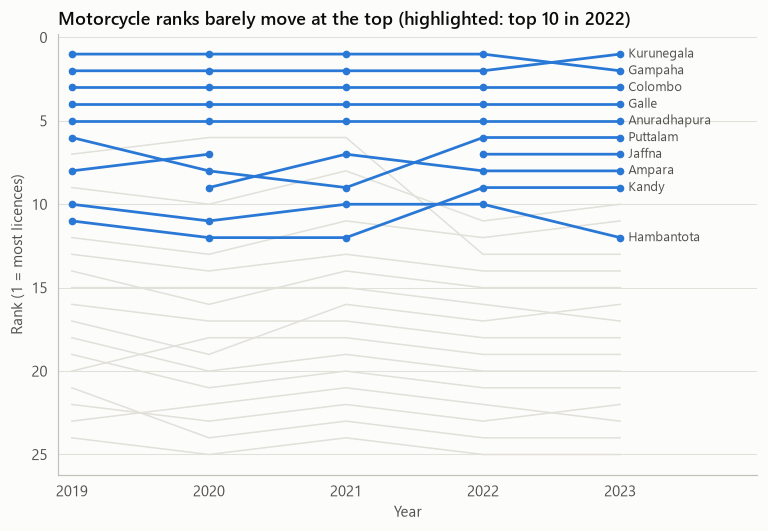

Saved fig20_motorcycle_rank_over_time.png


In [27]:
df["rank"] = df.groupby(["vehicle_type", "year"])["licence_count"].rank(ascending=False, method="min")
part = df[df["vehicle_type"] == "Motorcycle"]
table = part.pivot(index="district", columns="year", values="rank")
first_year = table[2022].nsmallest(10).index
fig, ax = plt.subplots(figsize=(8.2, 5.2))
for district in table.index:
    is_top = district in first_year
    ax.plot(table.columns, table.loc[district], color=BLUE if is_top else GRID, linewidth=1.8 if is_top else 1, marker="o" if is_top else None, markersize=4, zorder=3 if is_top else 1)
    if is_top and pd.notna(table.loc[district, 2023]):
        ax.text(2023.06, table.loc[district, 2023], district, fontsize=8.5, color=MUTED, va="center")
ax.invert_yaxis()
ax.set(title="Motorcycle ranks barely move at the top (highlighted: top 10 in 2022)", xlabel="Year", ylabel="Rank (1 = most licences)", xticks=sorted(df["year"].unique()), xlim=(2018.9, 2024))
ax.grid(axis="x", visible=False)
save_figure(fig, "motorcycle_rank_over_time")

**What it shows.** Motorcycle ranks across years, with the 2022 top 10 highlighted. Gaps are years with a missing value (Ampara 2019 and Jaffna 2021); those years rank 24 districts rather than 25.

**Why it matters.** The lines are almost flat. The only change at rank 1 is Kurunegala passing Gampaha in 2023, and that depends on a value flagged as uncertain (L11).

from_year,2019,2020,2021,2022
vehicle_type,,,,
Motorcycle,0.988,0.993,0.971,0.995
Car,0.992,0.990,0.993,0.990
Three-wheeler,0.989,0.995,0.937,0.995


from_year,2019,2020,2021,2022
vehicle_type,,,,
Motorcycle,5,5,5,5
Car,5,5,4,5
Three-wheeler,5,5,5,5


from_year,2020,2021
vehicle_type,,
Motorcycle,0.002,-0.581
Car,-0.057,-0.390
Three-wheeler,0.060,-0.053


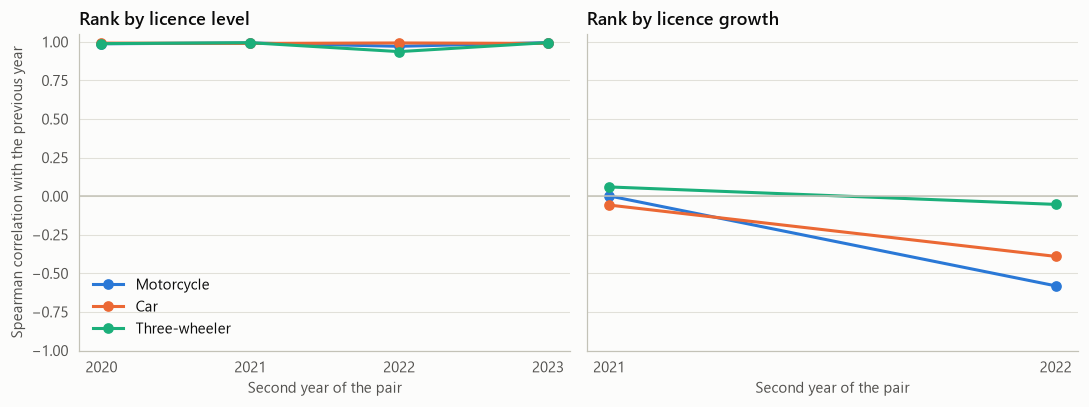

Saved fig21_rank_stability_level_vs_growth.png


In [28]:
def consecutive_stability(frame, value):
    rows = []
    for vehicle in VEHICLES:
        table = frame[frame["vehicle_type"] == vehicle].pivot(index="district", columns="year", values=value)
        for year in table.columns[:-1]:
            pair = table[[year, year + 1]].dropna()
            if len(pair) >= 5:
                top_a, top_b = set(pair[year].nlargest(5).index), set(pair[year + 1].nlargest(5).index)
                rows.append({"vehicle_type": vehicle, "from_year": year, "n": len(pair), "spearman": pair[year].corr(pair[year + 1], method="spearman"), "top_5_kept": len(top_a & top_b)})
    return pd.DataFrame(rows)

level_stability = consecutive_stability(df, "licence_count")
# Growth in 2023 is the target of the 2022 rows, so growth pairs stop at 2022.
growth_stability = consecutive_stability(df[df["year"] < HOLD_OUT_TARGET_YEAR], "licence_growth_log")
display(level_stability.pivot(index="vehicle_type", columns="from_year", values="spearman").loc[VEHICLES].round(3))
display(level_stability.pivot(index="vehicle_type", columns="from_year", values="top_5_kept").loc[VEHICLES])
display(growth_stability.pivot(index="vehicle_type", columns="from_year", values="spearman").loc[VEHICLES].round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, table, title in zip(axes, (level_stability, growth_stability), ("Rank by licence level", "Rank by licence growth")):
    for vehicle in VEHICLES:
        part = table[table["vehicle_type"] == vehicle]
        ax.plot(part["from_year"] + 1, part["spearman"], marker="o", markersize=6, color=VEHICLE_COLOURS[vehicle], label=vehicle)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set(title=title, xlabel="Second year of the pair", xticks=sorted(set(table["from_year"] + 1)), ylim=(-1, 1.05))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Spearman correlation with the previous year")
axes[0].legend(loc="lower left")
fig.tight_layout()
save_figure(fig, "rank_stability_level_vs_growth")
FINDINGS.update(level_rank_spearman_min=round(float(level_stability["spearman"].min()), 3), level_rank_spearman_max=round(float(level_stability["spearman"].max()), 3),
                growth_rank_spearman_min=round(float(growth_stability["spearman"].min()), 3), growth_rank_spearman_max=round(float(growth_stability["spearman"].max()), 3),
                growth_rank_spearman_median=round(float(growth_stability["spearman"].median()), 3),
                top_5_kept_min=int(level_stability["top_5_kept"].min()), top_5_kept_median=float(level_stability["top_5_kept"].median()))

**What it shows.** How closely each year's district ranking matches the previous year's. The left panel ranks by licence level, using all years. The right panel ranks by growth, stopping at 2022 because 2023 growth is the hold-out target.

**Why it matters.** Level rankings hardly change (0.937-0.995), but growth rankings do not persist at all (-0.581 to +0.060). A district growing fast one year is no more likely to do so the next.

In [29]:
# How much do flagged values move the rankings?
ordered = df.sort_values(key).copy()
ordered["rank_previous_year"] = ordered.groupby(["district", "vehicle_type"])["rank"].shift(1)
flagged_ranks = ordered[ordered["licence_flagged"]].copy()
flagged_ranks["rank_move"] = flagged_ranks["rank"] - flagged_ranks["rank_previous_year"]
columns = ["district", "vehicle_type", "year", "licence_count", "rank_previous_year", "rank", "rank_move", "licence_flag_ids"]

print("Flagged values inside a top 5:")
in_top_5 = flagged_ranks[flagged_ranks["rank"] <= 5].sort_values(["vehicle_type", "year", "rank"])
display(in_top_5[columns])
print("Largest rank moves at a flagged value:")
display(flagged_ranks.sort_values("rank_move", key=abs, ascending=False)[columns].head(6))

# Stability again, leaving flagged values out of the pairs. They are blanked in this
# temporary copy only; nothing is filled in, and the dataset is not changed.
without_flagged = df.assign(licence_count=df["licence_count"].where(~df["licence_flagged"]))
clean_stability = consecutive_stability(without_flagged, "licence_count")
comparison = level_stability.merge(clean_stability, on=["vehicle_type", "from_year"], suffixes=("_all", "_without_flagged"))
display(comparison.pivot(index="vehicle_type", columns="from_year", values="spearman_without_flagged").loc[VEHICLES].round(3))
display(comparison[["vehicle_type", "from_year", "spearman_all", "spearman_without_flagged", "top_5_kept_all", "top_5_kept_without_flagged"]]
        .sort_values("spearman_all").head(4).round(3))

motorcycle_top = df[(df["vehicle_type"] == "Motorcycle") & (df["rank"] <= 2)].sort_values(["year", "rank"])
print("Top two motorcycle districts each year:")
display(motorcycle_top.pivot(index="year", columns="rank", values="district"))

FINDINGS["flagged_values_in_top_5"] = len(in_top_5)
FINDINGS["flagged_values_in_top_5_list"] = [f"{r.district} {r.vehicle_type} {r.year} (rank {int(r.rank)})" for r in in_top_5.itertuples()]
FINDINGS["largest_flagged_rank_move"] = int(flagged_ranks["rank_move"].abs().max())
FINDINGS["level_rank_spearman_min_without_flagged"] = round(float(clean_stability["spearman"].min()), 3)
FINDINGS["top_5_kept_min_without_flagged"] = int(clean_stability["top_5_kept"].min())

Flagged values inside a top 5:


,district,vehicle_type,year,licence_count,rank_previous_year,rank,rank_move,licence_flag_ids
154,Kandy,Car,2023,52858.0,3.0,3.0,0.0,L03
204,Kurunegala,Motorcycle,2023,394975.0,2.0,1.0,-1.0,L11
101,Gampaha,Three-wheeler,2020,113127.0,1.0,2.0,1.0,L10
72,Colombo,Three-wheeler,2021,88051.0,1.0,2.0,1.0,L13
164,Kandy,Three-wheeler,2023,78853.0,3.0,3.0,0.0,L03


Largest rank moves at a flagged value:


,district,vehicle_type,year,licence_count,rank_previous_year,rank,rank_move,licence_flag_ids
43,Badulla,Three-wheeler,2022,37628.0,20.0,9.0,-11.0,L07
143,Kalutara,Motorcycle,2022,101043.0,6.0,13.0,7.0,L09
41,Badulla,Three-wheeler,2020,8150.0,17.0,21.0,4.0,L07
148,Kalutara,Three-wheeler,2022,35497.0,6.0,10.0,4.0,L09
2,Ampara,Car,2021,11912.0,15.0,13.0,-2.0,L12
281,Mullaitivu,Three-wheeler,2020,1056.0,23.0,25.0,2.0,L15


from_year,2019,2020,2021,2022
vehicle_type,,,,
Motorcycle,0.995,0.992,0.988,0.994
Car,0.994,0.991,0.995,0.986
Three-wheeler,0.996,0.991,0.999,0.995


,vehicle_type,from_year,spearman_all,spearman_without_flagged,top_5_kept_all,top_5_kept_without_flagged
10,Three-wheeler,2021,0.937,0.999,5,5
2,Motorcycle,2021,0.971,0.988,5,5
0,Motorcycle,2019,0.988,0.995,5,5
8,Three-wheeler,2019,0.989,0.996,5,4


Top two motorcycle districts each year:


rank,1.0,2.0
year,,
2019,Gampaha,Kurunegala
2020,Gampaha,Kurunegala
2021,Gampaha,Kurunegala
2022,Gampaha,Kurunegala
2023,Kurunegala,Gampaha


,count,mean,std,min,25%,50%,75%,max
vehicle_type,,,,,,,,
Motorcycle,25.0,1.9,1.4,0.0,1.0,2.0,2.0,7.0
Car,25.0,1.6,1.0,0.0,1.0,2.0,2.0,4.0
Three-wheeler,25.0,2.1,2.3,0.0,1.0,2.0,2.0,12.0


Largest rank movement:


,district,vehicle_type,rank_range
8,Badulla,Three-wheeler,12.0
28,Kalutara,Motorcycle,7.0
29,Kalutara,Three-wheeler,5.0
3,Anuradhapura,Car,4.0
63,Puttalam,Car,4.0
65,Puttalam,Three-wheeler,3.0


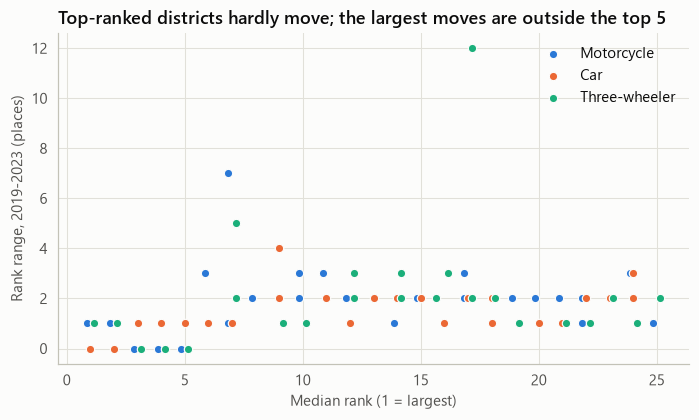

Saved fig22_rank_movement_by_district_size.png


In [30]:
# How far does each district's motorcycle rank move across all years?
movement = df.groupby(["district", "vehicle_type"])["rank"].agg(lambda s: s.max() - s.min()).rename("rank_range").reset_index()
display(movement.groupby("vehicle_type")["rank_range"].describe().loc[VEHICLES].round(1))
print("Largest rank movement:")
display(movement.sort_values("rank_range", ascending=False).head(6))

size_vs_movement = df.groupby(["district", "vehicle_type"])["rank"].median().rename("median_rank").reset_index().merge(movement)
fig, ax = plt.subplots(figsize=(7.4, 3.9))
for vehicle in VEHICLES:
    part = size_vs_movement[size_vs_movement["vehicle_type"] == vehicle]
    jitter = {"Motorcycle": -0.15, "Car": 0, "Three-wheeler": 0.15}[vehicle]
    ax.scatter(part["median_rank"] + jitter, part["rank_range"], s=30, color=VEHICLE_COLOURS[vehicle], edgecolor=SURFACE, linewidth=0.8, label=vehicle)
ax.set(title="Top-ranked districts hardly move; the largest moves are outside the top 5", xlabel="Median rank (1 = largest)", ylabel="Rank range, 2019-2023 (places)")
ax.legend()
save_figure(fig, "rank_movement_by_district_size")
FINDINGS["rank_range_median"] = {v: float(movement.loc[movement["vehicle_type"] == v, "rank_range"].median()) for v in VEHICLES}
FINDINGS["rank_range_max"] = int(movement["rank_range"].max())

**What it shows.** How many places each district's rank moved between 2019 and 2023, against its typical rank.

**Why it matters.** The median movement is 2 places for every vehicle type. Top-ranked districts barely move, whereas the largest moves are in mid-table and are linked to flagged values: Badulla three-wheelers (12 places) and Kalutara motorcycles (7 places).

### Finding 11: Rankings are stable, but mostly measure district size

**1. What did we discover?** Consecutive-year rank correlations for levels are 0.937-0.995, and at least 4 of the top 5 districts stay in place each time. Growth rankings do not persist (-0.581 to +0.060). Five flagged values sit inside a top 5, and flagged values cause the largest rank moves. Without flagged values, the lowest level correlation rises to 0.986.

**2. Why does it matter?** The dataset supports a **descriptive** ranking of fleet size. It does not show that a forecast ranking adds anything beyond this year's order, and it does not support claims about which districts are growing fastest.

**3. How could it affect our ML methodology?** Evaluate rankings against 'keep this year's order' as a baseline. Use Spearman correlation, along with top-N overlap, per vehicle type. Present districts in broad opportunity bands rather than exact positions, especially below the top 5. Any growth-based ranking would need strong caveats. Rankings cannot be per capita until population data is collected.

**Observation or assumption?** **Observation:** the rank correlations and moves. **Assumption:** that fleet size indicates service opportunity. This is the project's proxy assumption, and it cannot be tested here because no mechanic-demand data exists. Competition between mechanics, vehicle age and prices are not measured.

## 14. Answers to the research questions

| Question | Answer from the data | Confidence |
|---|---|---|
| How do licence counts vary across districts? | Very widely. Over 98% of variation in log licences is between districts, and the top 5 hold 45-67%. The vehicle mix also differs by district. | High |
| How stable are fleet indicators over time? | Licences are very stable (median change 4.0%). Registrations are not, falling by 94.0% from 2019 to 2022. | High for the pattern; the cause is an assumption |
| Which features appear useful? | `licence_count` and `vehicle_type` for level. Nothing is strongly related to next-year change. Registration growth looks useful only before year effects are removed. | Medium: based on correlations in two to three target years |
| How might suspicious values affect results? | They drive the extreme tails and the largest rank moves, and could flatter or penalise models. Medians and top ranks are less affected. | Medium: flagged values are uncertain, not proven wrong |
| Does the dataset support meaningful rankings? | Yes as a stable description of fleet size, in broad bands. No as evidence of growth rankings or of forecasting skill beyond this year's order. | Medium: depends on the proxy assumption |

## 15. Recommendations for the ML phase

1. **Baselines first.** Use "same as last year" and a moving average. A model is only useful if it beats them.
2. **Rolling-origin validation.** With full licence features, this gives two folds: train on target year 2021 and test on 2022, then train on 2021-2022 and test on 2023. Keep 2023 as the final test only.
3. **Features.** Start with `licence_count`, `vehicle_type` and `licence_growth_log`. Test `licence_rolling_std_3` and registration features as add-ons on the same rows. Drop `licence_lag_2`, and do not use lag 1 and the rolling mean alongside `licence_count` without regularisation.
4. **Target scale.** Keep raw counts for reporting. Compare training on log level and on log change.
5. **Models.** Keep them simple and regularised, given about 219 rows. Ridge is a natural starting point. Random Forest and XGBoost need strong regularisation, and trees cannot predict beyond the values seen in training unless they predict change.
6. **Metrics.** Use MAE, MAPE and MASE on the original scale; Spearman and top-N overlap per vehicle type; and skill on next-year change. Do not rely on R-squared on levels.
7. **Data quality.** Report every result with and without flagged rows. Review the 8 new outlier candidates against the PDFs.
8. **Independence.** Rows from one district are related, so avoid random splits, fit any scaling inside each training fold, and avoid a raw district identifier.
9. **Honest conclusions.** If ML does not beat persistence, report it. That is a valid answer to RQ3.

## 16. Output and integrity checks

The final cell saves the findings and asserts every headline number quoted in the explanations above, so the text cannot drift from the data without this notebook failing.

In [31]:
expected = {
    "rows": 375, "columns": 39, "target_values": 299, "development_rows": 224, "feature_target_max_target_year": 2022,
    "duplicate_keys": 0, "missing_licence": 4, "missing_total_registrations_rows": 36, "usable_licence_features": 219,
    "usable_with_registrations": 180, "usable_with_lag_2": 145, "skew_raw": 2.29, "skew_log": -0.85, "licence_mean": 57830,
    "licence_median": 31233, "licence_min": 254, "licence_max": 394975, "motorcycle_share_min": 40.0, "motorcycle_share_max": 93.0,
    "median_absolute_change_pct": 4.0, "share_within_10_pct": 76.3, "values_beyond_50_pct": 6, "registrations_fall_2019_2022_pct": 94.0,
    "robust_outliers": 28, "robust_outliers_documented": 20, "robust_outliers_new": 8, "target_skew_raw": 2.33, "target_skew_log": -0.84,
    "dev_median_absolute_next_change_pct": 4.1, "flagged_licence_values": 30, "flagged_targets": 24, "flagged_targets_in_hold_out": 9,
    "districts_with_issue": 13, "level_rank_spearman_min": 0.937, "level_rank_spearman_max": 0.995, "growth_rank_spearman_min": -0.581,
    "growth_rank_spearman_max": 0.06, "top_5_kept_min": 4, "level_rank_spearman_min_without_flagged": 0.986, "flagged_values_in_top_5": 5,
    "largest_flagged_rank_move": 11, "rank_range_max": 12, "sensitivity_clean_rows": 179, "sensitivity_all_rows": 220,
}
differences = {k: (FINDINGS[k], v) for k, v in expected.items() if FINDINGS[k] != v}
assert not differences, f"A number in the explanations no longer matches the data: {differences}"
assert FINDINGS["between_district_variance_share"] == {"Motorcycle": 98.6, "Car": 98.7, "Three-wheeler": 98.4}
assert FINDINGS["top_5_share_2022"] == {"Motorcycle": 45.4, "Car": 67.0, "Three-wheeler": 46.4}
assert FINDINGS["index_2023_all_series"] == {"Motorcycle": 105.9, "Car": 99.8, "Three-wheeler": 89.0}
assert FINDINGS["index_2023_excluding_flagged_series"] == {"Motorcycle": 103.0, "Car": 99.5, "Three-wheeler": 97.5}
assert FINDINGS["flag_comparison"]["median_abs_change_flagged"] == 38.3 and FINDINGS["flag_comparison"]["median_abs_change_unflagged"] == 3.8
assert FINDINGS["sensitivity_change_abs"] == {"all_median": 4.1, "clean_median": 3.5, "all_mean": 9.4, "clean_mean": 5.3}
assert round(FINDINGS["feature_target"]["licence_count"]["rho_change_within_year"], 2) == -0.21
assert round(FINDINGS["feature_target"]["total_registrations_growth_log"]["rho_change_within_year"], 2) == 0.04
assert round(FINDINGS["feature_target"]["total_registrations_growth_log"]["rho_with_next_change"], 2) == 0.16
print("All numbers quoted in the explanations match the data.")

All numbers quoted in the explanations match the data.


In [32]:
FINDINGS["figures"] = FIGURES
FINDINGS["figure_count"] = len(FIGURES)
(OUTPUT_DIR / "eda_findings.json").write_text(json.dumps(FINDINGS, indent=2, default=str) + "\n", encoding="utf-8", newline="\n")

# The notebook must leave the dataset exactly as it found it.
assert hashlib.sha256(DATASET_CSV.read_bytes()).hexdigest() == manifest["dataset_sha256"]
print(f"Charts created: {len(FIGURES)}")
print("Dataset unchanged:", manifest["dataset_version"])

Charts created: 22
Dataset unchanged: modelling_dataset_v2_04eaecafd7e1
